# 02. Environmental GWAS

Evaluate environmental associations for 31 variables, summarize variant associations at the gene level with MAGMA, and interpret them using flowering-time and cis-eQTL annotations.


# 02. 环境 GWAS

分析 31 个环境变量与遗传变异的关联，使用 MAGMA 将位点关联汇总至基因层面，并结合开花时间及 cis-eQTL 注释进行解释。


### Environment setup


### 环境设置


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
from datetime import datetime
from time import perf_counter
import pandas as pd
import yaml

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
os.makedirs(results_dir, exist_ok=True)
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

from src.plot import set_plot_style
set_plot_style()

print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')
print(f"Environment prefix: {os.environ.get('CONDA_PREFIX', '<not set>')}")

Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python
Environment prefix: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base


## 1. Population and environments of sorghum landraces


## 1. 高粱地方品种的群体与环境


### Landrace metadata

Sample identities, botanical groups, collection locations and environmental variables provide the basis for describing the landrace population and its environments.


### 地方品种元数据

样本信息、植物学分组、采集地点及环境变量用于描述地方品种群体及其所处环境。


In [2]:
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
landrace_metadata_df = pd.read_csv(landrace_metadata_csv)
landrace_metadata_df

,ISnum,PInumber,LIB,Sample,WASAP,PlantName,Germplasm,BotanicalType,Latitude,Longitude,...,bio17,bio19,alt,NTO,CLYPPT,annualPET,TPH,topoWet,PlotBotanicalType,min_dist_to_striga
0,NaN,NaN,IZII,Ni205_177,Ni205,NaN,Landrace,Durra-caudatum,13.232833,8.229278,...,0,0,460.0,373.0,6.0,2017.839966,93.0,13.02,Durra-caudatum,62.236593
1,NaN,NaN,IZIY,Ni295_302,Ni295,El Dan Mato,Landrace,Durra-caudatum,13.123722,7.008417,...,0,0,411.0,368.0,8.0,1994.109985,122.0,12.96,Durra-caudatum,22.765923
2,NaN,NaN,IZIX,Ni293_172,Ni293,Ja Dawa,Landrace,Durra-caudatum,13.024194,7.046028,...,0,0,431.0,412.0,9.0,1982.750000,107.0,12.64,Durra-caudatum,23.155054
3,NaN,NaN,IZJH,Sen053_041,Sn053,Diériker Ndélé,Landrace,Guinea,15.786164,-16.523998,...,7,46,8.0,626.0,18.0,1601.599976,231.0,13.84,Guinea,25.733178
4,NaN,NaN,IZIP,Ni224_310,Ni224,Ja Dawa,Landrace,Durra-caudatum,13.247722,7.736417,...,0,0,428.0,424.0,9.0,1997.520020,96.0,12.95,Durra-caudatum,57.367592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,IS9524,PI563289,IZKC,PI563289,NaN,IS9524,Cultivated,Kafir-durra,-25.746111,28.188056,...,173,256,1335.0,1121.0,27.0,1541.000000,764.0,11.27,Kafir-durra,1131.597982
439,IS9883,PI571271,IPEJ,PI571271,NaN,IS9883,Landrace,Caudatum,11.189999,24.149999,...,0,0,559.0,551.0,36.0,2213.679932,120.0,14.38,Caudatum,198.525796
440,IS9885,PI571273,IXPG,PI571273,NaN,IS9885,Landrace,Caudatum,6.480000,29.420000,...,135,5469,479.0,665.0,27.0,1959.829956,245.0,13.51,Caudatum,209.075913
441,IS9911,PI571292,IPEK,PI571292,NaN,IS9911,Landrace,Caudatum,11.016667,29.716667,...,2,4130,513.0,744.0,40.0,2091.260010,276.0,12.11,Caudatum,1.068439


### 1.1 Population distribution and relatedness


### 1.1 群体分布与亲缘关系


Show the geographic distribution of landraces, colored by botanical group. Samples lacking coordinates or group information are excluded. Legend counts include all retained samples, including those outside the displayed map extent.


展示地方品种的地理分布，以颜色区分植物学分组。排除缺少采集坐标或分组信息的样本。图例中的样本数包含所有保留样本，包括位于地图显示范围之外的样本。


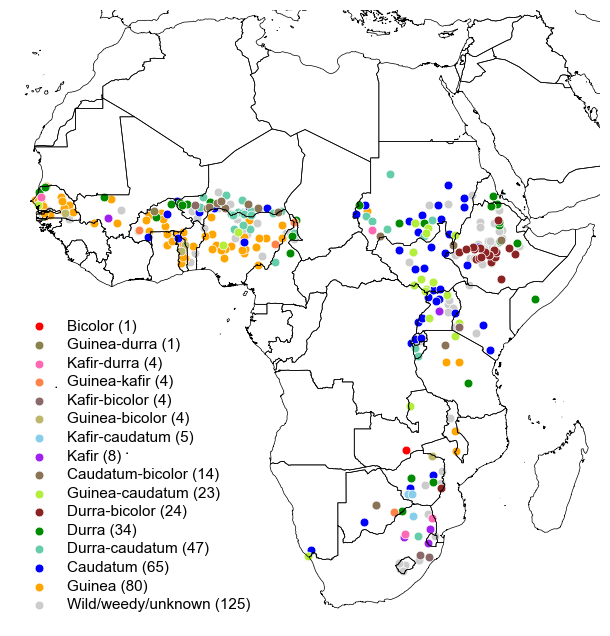

Mapped samples: 443 / 443
Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_botanical_map.figS1.pdf


In [3]:
from src.env_vars import landraces_botanical_map_plotter

world_map_shp = f'{source_dir}/natural_earth/ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp'
save_fig_path = f'{results_dir}/landraces_botanical_map.figS1.pdf'
longitude_limit = (-20, 52)
latitude_limit = (-37, 38)

botanical_map_df = landraces_botanical_map_plotter(
    landrace_metadata_df, save_fig_path, world_map_shp,
    longitude_limit=longitude_limit, latitude_limit=latitude_limit, figsize=(8, 8),
)
print(f'Mapped samples: {len(botanical_map_df):,} / {len(landrace_metadata_df):,}')
print(f'Figure: {save_fig_path}')


#### Infer genetic relationships among landraces

Use the imputed genotypes, which have no missing values, to describe genetic relationships among landraces. Remove rare and highly heterozygous SNPs and reduce redundancy among linked markers through LD pruning. Calculate identity by state (IBS) and infer a neighbor-joining tree from the resulting genetic distances using FastME.


#### 推断地方品种间的遗传关系

使用经过基因型填补、无缺失值的数据，描述地方品种间的遗传关系。去除稀有及高杂合 SNP，并通过 LD pruning 减少连锁标记的冗余。计算状态一致性（identity by state，IBS），再依据遗传距离使用 FastME 构建邻接树。


In [4]:
from src.ibs import build_ibs_nj_tree

landraces_vcf_file = f'{results_dir}/landraces.vcf.gz'
genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
min_maf = 0.01
max_het = 0.01
ld_window_size = 15000
r2_threshold = 0.5
kinship_seed = 42
kinship_n_jobs = project_config['resources']['interactive']['cores']
kinship_output_prefix = f'{results_dir}/landraces_snp_pruned'
kinship_result_prefix = f'{kinship_output_prefix}.win{ld_window_size}.miss0.5.maf{min_maf}.het{max_het}.rq{r2_threshold}'
nj_prefix = kinship_result_prefix
snp_pruned_vcf_file = f'{kinship_result_prefix}.vcf.gz'
nj_tree_file = f'{kinship_result_prefix}.ibs_dist.nj.tree'
kinship_result_files = [
    snp_pruned_vcf_file, f'{snp_pruned_vcf_file}.tbi',
    f'{kinship_result_prefix}.ibs.matrix', f'{kinship_result_prefix}.ibs_dist.matrix',
    f'{kinship_result_prefix}.ibs_dist.phylip', nj_tree_file,
]

stage_start = perf_counter()
if all(os.path.exists(path) for path in kinship_result_files):
    print(f'[{datetime.now():%H:%M:%S}] Reusing IBS matrices and NJ tree: {nj_tree_file}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Pruning SNPs and building IBS/NJ results with {kinship_n_jobs} workers', flush=True)
    kinship_results = build_ibs_nj_tree(
        landraces_vcf_file, genome_fasta_file, output_prefix=kinship_output_prefix,
        only_snps=True, min_maf=min_maf, max_het=max_het,
        ld_window_size=ld_window_size, r2_threshold=r2_threshold,
        random_seed=kinship_seed, n_jobs=kinship_n_jobs,
    )
    if not all(os.path.exists(path) for path in kinship_result_files):
        raise RuntimeError('Expected pruned VCF, IBS matrices and NJ tree are incomplete.')
print(f'[{datetime.now():%H:%M:%S}] IBS/NJ results ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:34:42] Reusing IBS matrices and NJ tree: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_snp_pruned.win15000.miss0.5.maf0.01.het0.01.rq0.5.ibs_dist.nj.tree
[04:34:42] IBS/NJ results ready (0.0 s)


#### Plot genetic relationships

Color the neighbor-joining tree by botanical group to examine how these groups are distributed across the genetic relationships among samples. Samples without a matched botanical group are shown in gray.


#### 展示遗传关系

在邻接树上以颜色区分植物学分组，观察各分组在样本遗传关系中的分布。无法匹配植物学分组的样本以灰色表示。


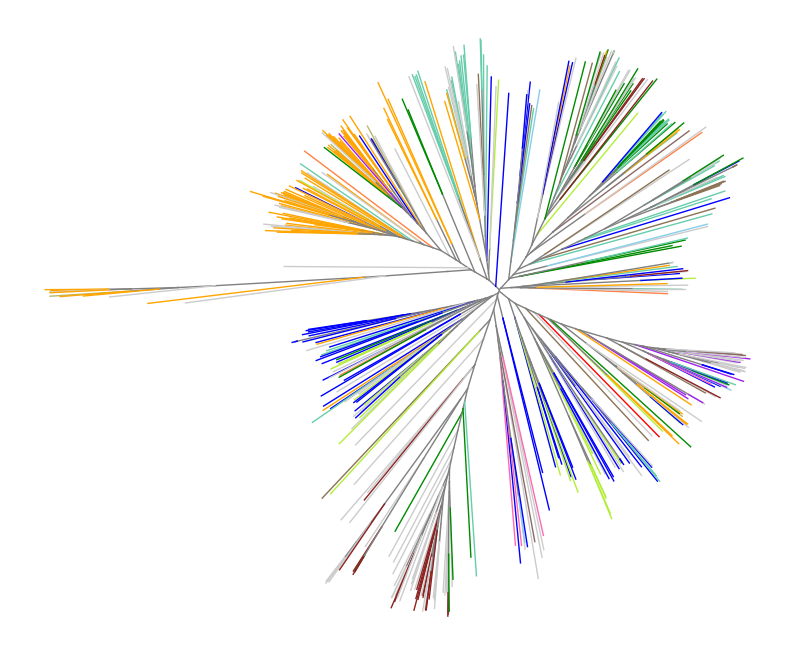

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_nj_tree.figS1.pdf


In [5]:
from src.env_vars import nj_tree_plotter

save_fig_path = f'{results_dir}/landraces_nj_tree.figS1.pdf'
nj_tree_plotter(nj_tree_file, landrace_metadata_df, save_fig_path=save_fig_path, figsize=(10, 10))
print(f'Figure: {save_fig_path}')


### 1.2 Population genomic landscape

Describe linkage disequilibrium and the distributions of genomic annotations and genetic variation across the landrace genome.


### 1.2 群体基因组特征

描述地方品种群体的连锁不平衡，以及基因组注释和遗传变异沿染色体的分布。


#### 1.2.1 Linkage disequilibrium

Characterize how linkage disequilibrium (LD) declines with physical distance using genome-wide QC variants (SNPs and indels). Calculate mean r² between variants within each chromosome over distances up to 20 kb; pairs with undefined r² are excluded.


#### 1.2.1 连锁不平衡

使用全基因组质控变异（SNP和indel），描述连锁不平衡（LD）随物理距离的衰减。在各染色体内计算距离不超过 20 kb 的变异对的平均 r²，排除 r² 未定义的位点对。


In [6]:
from src.ld import calculate_ld_decay

landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_qc_stat_h5 = f'{landraces_qc_vcf_file}.var_stat.h5'
ld_max_distance = 20000
ld_bin_size = 50
ld_pool_num = 20
ld_force_recompute = False
ld_tag = f'{landraces_qc_vcf_file}.ld_decay'
ld_decay_cache = f'{ld_tag}.csv.gz'
ld_figure_file = f'{ld_tag}.pdf'
ld_half_dist_csv = f'{ld_tag}.threshold_distances.csv.gz'

stage_start = perf_counter()
if not ld_force_recompute and os.path.exists(ld_decay_cache):
    print(f'[{datetime.now():%H:%M:%S}] Reusing LD decay statistics: {ld_decay_cache}', flush=True)
    ld_decay_df = pd.read_csv(ld_decay_cache)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating LD decay with {ld_pool_num} workers', flush=True)
    with pd.HDFStore(landraces_qc_stat_h5, mode='r') as ld_store:
        ld_sites = pd.concat([ld_store[key] for key in ld_store.keys()], ignore_index=True)
    ld_sites = ld_sites.sort_values(['CHROM', 'POS']).reset_index(drop=True)
    ld_decay_df = calculate_ld_decay(
        ld_sites, landraces_qc_vcf_file, max_decay_size=ld_max_distance,
        curve_bin_size=ld_bin_size, pool_num=ld_pool_num,
    )
    temporary_csv = f'{ld_decay_cache}.tmp'
    ld_decay_df.to_csv(temporary_csv, index=False, compression='gzip')
    os.replace(temporary_csv, ld_decay_cache)
print(f'[{datetime.now():%H:%M:%S}] LD decay statistics ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:34:45] Reusing LD decay statistics: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.csv.gz
[04:34:45] LD decay statistics ready (0.0 s)


##### Plot LD decay

Compare LD decay among chromosomes and estimate the distance at which mean r² first falls below 0.5 by interpolation between adjacent observed bins. The displayed origin (0 bp, r² = 1) is a plotting convention and is excluded from this estimate.


##### 绘制 LD 衰减曲线

比较不同染色体的 LD 衰减，通过相邻观测分箱间的插值，估计平均 r² 首次降至 0.5 以下的距离。图中起点（0 bp、r² = 1）仅用于展示，不参与距离估计。


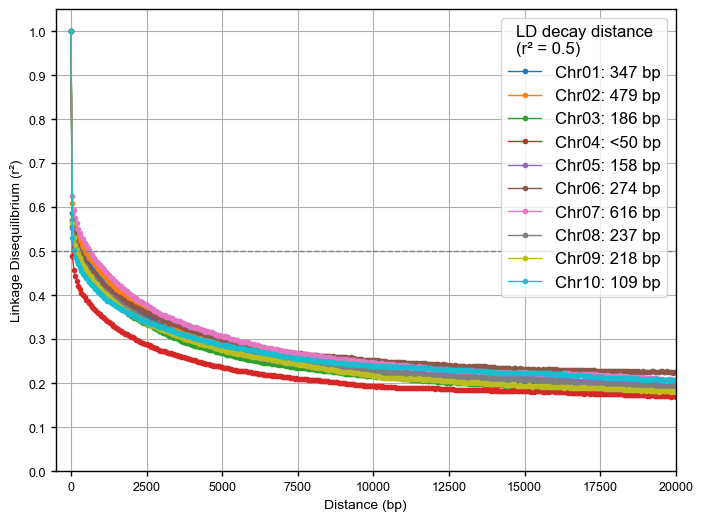

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.pdf
Figure data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.csv.gz


,CHROM,half_ld_value,half_ld_dist,status
0,Chr01,0.5,347.529496,reached
1,Chr02,0.5,479.221340,reached
2,Chr03,0.5,186.479450,reached
3,Chr04,0.5,NaN,below_in_first_bin
4,Chr05,0.5,158.289722,reached
5,Chr06,0.5,274.244747,reached
6,Chr07,0.5,616.334547,reached
7,Chr08,0.5,237.270528,reached
8,Chr09,0.5,218.100606,reached
9,Chr10,0.5,109.921828,reached


In [7]:
import matplotlib.pyplot as plt
from src.ld import plot_ld_decay

ld_half_value = 0.5
ld_decay_df = pd.read_csv(ld_decay_cache)
ld_fig, ld_ax, ld_half_dist_df = plot_ld_decay(
    ld_decay_df, half_ld_value=ld_half_value, figsize=(8, 6),
    xlim=(-500, ld_max_distance), save_fig_path=ld_figure_file,
)
ld_half_dist_df.to_csv(ld_half_dist_csv, index=False, compression='gzip')
plt.show()
print(f'Figure: {ld_figure_file}')
print(f'Figure data: {ld_decay_cache}')
ld_half_dist_df


##### Multiscale LD decay

Extend the analysis to longer distances to examine broader patterns of LD. Evaluate all eligible variant pairs within 200 kb and estimate mean r² from sampled pairs at larger distances, including a final distance class above 50 Mb.


##### 多尺度 LD 衰减

将分析扩展至更远距离，观察更大尺度上的 LD 特征。200 kb 以内使用全部符合条件的变异对；更远距离通过抽样位点对估计平均 r²，最后一组包含距离大于 50 Mb 的位点对。


In [8]:
from src.ld import calculate_multiscale_ld_decay

landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_qc_stat_h5 = f'{landraces_qc_vcf_file}.var_stat.h5'
multiscale_ld_csv = f'{landraces_qc_vcf_file}.multiscale_ld_decay.csv.gz'
multiscale_ld_pdf = f'{landraces_qc_vcf_file}.multiscale_ld_decay.pdf'
multiscale_ld_workers = 20

stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing multiscale LD statistics with {multiscale_ld_workers} workers', flush=True)
multiscale_ld_df = calculate_multiscale_ld_decay(
    landraces_qc_stat_h5, landraces_qc_vcf_file, full_distance=200_000,
    max_pairs_per_bin=50_000, random_seed=42,
    pool_num=multiscale_ld_workers, cache_file=multiscale_ld_csv,
)
print(f'[{datetime.now():%H:%M:%S}] Multiscale LD statistics ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:34:46] Preparing multiscale LD statistics with 20 workers
Reading existing multiscale LD CSV: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.csv.gz
[04:34:46] Multiscale LD statistics ready (0.0 s)


##### Plot multiscale LD decay

Compare mean r² among chromosomes across distance classes. Classes are equally spaced on the horizontal axis, so their spacing does not represent physical distance. The displayed origin (0, 1) is not an observed value.


##### 绘制多尺度 LD 衰减曲线

比较各染色体在不同距离区间内的平均 r²。横轴区间等间距排列，其间距不代表实际物理距离。图中起点（0, 1）不是观测值。


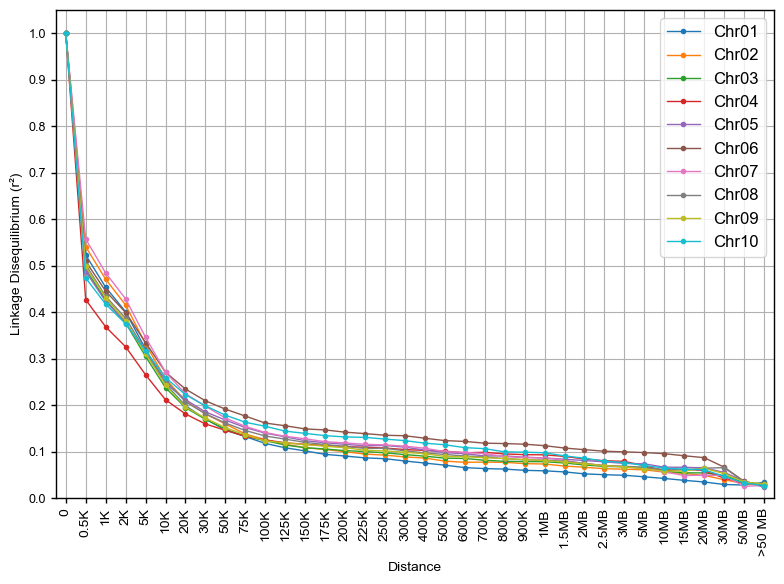

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.pdf
Figure data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.csv.gz


In [9]:
import matplotlib.pyplot as plt
from src.ld import plot_multiscale_ld_decay

multiscale_ld_df = pd.read_csv(multiscale_ld_csv)
multiscale_ld_fig, multiscale_ld_ax = plot_multiscale_ld_decay(
    multiscale_ld_df, save_fig_path=multiscale_ld_pdf, figsize=(8, 6),
)
plt.show()
print(f'Figure: {multiscale_ld_pdf}')
print(f'Figure data: {multiscale_ld_csv}')


##### Identify haplotype blocks

Identify haplotype blocks with PLINK from the unpruned QC SNP panel. Their lengths complement the LD decay curves by describing the extent of local blocks of linked variation.


##### 识别单倍型区块

使用未做 LD pruning 的质控 SNP，通过 PLINK 识别单倍型区块。区块长度描述局部连锁变异的延伸范围，与 LD 衰减曲线相互补充。


In [10]:
import subprocess

# PLINK blocks use the existing QC SNP panel; no LD pruning is applied.
landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
plink_blocks_dir = f'{results_dir}/landraces_qc_maf0.05_het0.05.plink_blocks'
plink_force_recompute = False
plink_maf = 0.05
plink_max_kb = 500
plink_threads = 20
plink_parallel = 4
plink_block_memory_mb = 64000
plink_preprocess_memory_mb = 16000
plink_blocks_prefix = f'{plink_blocks_dir}/landraces.maf{plink_maf}.biallelic.blocks_max{plink_max_kb}kb'
plink_blocks_result_file = f'{plink_blocks_prefix}.project_chr.blocks.det'

stage_start = perf_counter()
reuse_blocks = os.path.exists(plink_blocks_result_file) and not plink_force_recompute
if reuse_blocks:
    print(f'[{datetime.now():%H:%M:%S}] Reusing PLINK blocks: {plink_blocks_result_file}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating PLINK blocks', flush=True)
    subprocess.run([
        'bash', f'{project_dir}/src/plink_block.sh',
        '--vcf', landraces_qc_vcf_file, '--out-dir', plink_blocks_dir,
        '--prefix', 'landraces', '--maf', str(plink_maf),
        '--max-kb', str(plink_max_kb), '--threads', str(plink_threads),
        '--parallel', str(plink_parallel),
        '--block-memory-mb', str(plink_block_memory_mb),
        '--preprocess-memory-mb', str(plink_preprocess_memory_mb),
    ], check=True)
ld_blocks = pd.read_csv(plink_blocks_result_file, sep=r'\s+')
print(f'[{datetime.now():%H:%M:%S}] PLINK blocks ready ({perf_counter() - stage_start:.1f} s)', flush=True)
print(f'Blocks: {len(ld_blocks):,}')
ld_blocks.groupby('CHR').size().rename('BLOCK_COUNT').to_frame()


[04:34:47] Reusing PLINK blocks: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.project_chr.blocks.det
[04:34:48] PLINK blocks ready (1.0 s)
Blocks: 133,207


,BLOCK_COUNT
CHR,
Chr01,16766
Chr02,15428
Chr03,16549
Chr04,13845
Chr05,15528
Chr06,11476
Chr07,11438
Chr08,10737
Chr09,10940


##### Plot haplotype-block lengths

Show the genome-wide distribution of block lengths, counting each block once. Lengths below 10 kb are grouped in 0.2 kb intervals; the final bar combines all blocks ≥10 kb.


##### 绘制单倍型区块长度分布

展示全基因组的 block 长度分布，每个 block 计一次。小于 10 kb 的长度按 0.2 kb 分箱，最后一根柱汇总所有大于等于 10 kb 的 block。


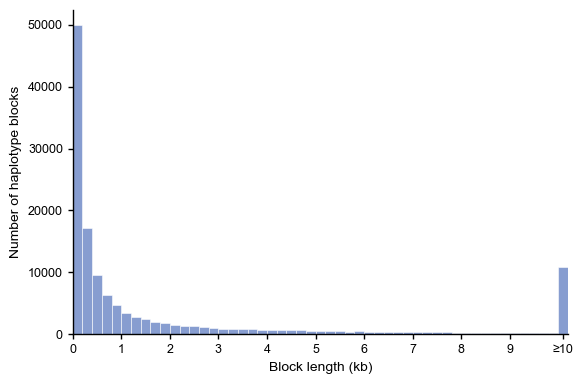

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.length_distribution.pdf
Plot data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.length_distribution.csv.gz


In [11]:
import numpy as np
import matplotlib.pyplot as plt

block_lengths_df = pd.read_csv(plink_blocks_result_file, sep=r'\s+', usecols=['KB'])
block_lengths_kb = block_lengths_df['KB'].to_numpy()
block_length_plot_prefix = f'{plink_blocks_prefix}.length_distribution'
block_length_cutoff_kb = 10
block_length_bin_kb = 0.2

bin_edges = np.linspace(0, block_length_cutoff_kb, round(block_length_cutoff_kb / block_length_bin_kb) + 1)
block_counts, _ = np.histogram(block_lengths_kb[block_lengths_kb < block_length_cutoff_kb], bins=bin_edges)
block_length_plot_df = pd.DataFrame({
    'LEFT_KB': bin_edges,
    'RIGHT_KB': np.r_[bin_edges[1:], np.inf],
    'BLOCK_COUNT': np.r_[block_counts, (block_lengths_kb >= block_length_cutoff_kb).sum()],
    'BIN_LABEL': [f'{left:g}–{right:g}' for left, right in zip(bin_edges[:-1], bin_edges[1:])]
                 + [f'≥{block_length_cutoff_kb:g}'],
})

block_length_fig, block_length_ax = plt.subplots(figsize=(6, 4))
block_length_ax.bar(
    block_length_plot_df['LEFT_KB'] + block_length_bin_kb / 2,
    block_length_plot_df['BLOCK_COUNT'], width=block_length_bin_kb,
    color='#879DD0', edgecolor='white', linewidth=0.4,
)
block_length_ax.set_xlabel('Block length (kb)')
block_length_ax.set_ylabel('Number of haplotype blocks')
block_length_ax.set_xlim(0, block_length_cutoff_kb + block_length_bin_kb)
block_length_ax.set_xticks(
    [*range(block_length_cutoff_kb), block_length_cutoff_kb + block_length_bin_kb / 2],
    [*map(str, range(block_length_cutoff_kb)), f'≥{block_length_cutoff_kb}'],
)
block_length_ax.spines[['top', 'right']].set_visible(False)
block_length_fig.tight_layout()
block_length_plot_df.to_csv(f'{block_length_plot_prefix}.csv.gz', index=False, compression='gzip')
block_length_fig.savefig(f'{block_length_plot_prefix}.pdf', bbox_inches='tight')
block_length_fig.savefig(f'{block_length_plot_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Figure: {block_length_plot_prefix}.pdf')
print(f'Plot data: {block_length_plot_prefix}.csv.gz')


#### 1.2.2 Population genomic landscape

Describe the distributions of genomic features, nucleotide diversity and recombination across chromosomes. Calculate local statistics in 500 bp windows and summarize them at the 1 Mb scale for comparison with annotation coverage and haplotype-block lengths.


#### 1.2.2 群体基因组特征

描述基因组功能区域、核苷酸多样性和重组率沿染色体的分布。以 500 bp 窗口计算局部统计，再汇总至 1 Mb 尺度，与注释覆盖率及单倍型区块长度进行对照。


##### Summarize local genomic variation

Summarize annotation coverage, nucleotide diversity (π), Tajima’s D and recombination rate in 500 bp windows, including windows without variants. Variant counts include SNPs and indels, and diversity is calculated without additional MAF filtering. Diversity is undefined in windows with fewer than three variant records; Tajima’s D also requires at least three segregating sites.


##### 汇总局部基因组变异

以 500 bp 窗口汇总注释覆盖率、核苷酸多样性（π）、Tajima’s D 和重组率，包括无变异窗口。变异数包含 SNP 和 indel，多样性计算不增加 MAF 过滤。少于三条变异记录的窗口不计算多样性；Tajima’s D 还要求至少三个分离位点。


In [12]:
from src.contexts import (
    get_genome_windows_contexts, get_genome_window_statistics, save_context_table,
)

landraces_vcf_file = f'{results_dir}/landraces.vcf.gz'
genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
repeat_gff_file = f'{source_dir}/Sbicolor_730_v5.1.repeatmasked_assembly_v5.0.gff3.gz'
recombination_file = f'{source_dir}/avg_cM_genomewide_NAM_population.csv.gz'
bed_files = {name: f'{source_dir}/{name}s.v5.bed.gz' for name in ['ACR', 'UMR']}
window_size = 500
min_variant_count = 3
n_jobs = 20
force_recompute = False
genome_windows_contexts_h5 = f'{results_dir}/genome_windows_contexts.b{window_size}.h5'
statistics_columns = ['VARIANT_COUNT', 'SNP_COUNT', 'PI', 'TajimaD', 'meanCmPerMb']

stage_start = perf_counter()
reuse_windows = os.path.exists(genome_windows_contexts_h5) and not force_recompute
if reuse_windows:
    genome_windows_contexts_df = pd.read_hdf(genome_windows_contexts_h5, key='df')
    reuse_windows = (
        all(column in genome_windows_contexts_df for column in statistics_columns + ['REPEAT_FRACTION'])
        and not any(column.startswith(('low_pi', 'med_pi', 'high_pi'))
                    for column in genome_windows_contexts_df.columns)
        and not any(column in genome_windows_contexts_df for column in ['LD_r2', 'ThetaW', 'DAF'])
    )
if reuse_windows:
    print(f'[{datetime.now():%H:%M:%S}] Reusing genome window table: {genome_windows_contexts_h5}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating annotations and diversity in {window_size} bp windows', flush=True)
    genome_windows_contexts_df = get_genome_windows_contexts(
        genome_fasta_file, gff_file, repeat_gff_file, bed_files=bed_files,
        recombination_file=recombination_file, window_size=window_size,
        bed_zero_based=False,
    )
    genome_statistics_df = get_genome_window_statistics(
        genome_fasta_file, landraces_vcf_file, recombination_file, window_size=window_size,
        min_variant_count=min_variant_count, n_jobs=n_jobs,
    )
    genome_windows_contexts_df = genome_windows_contexts_df.merge(
        genome_statistics_df, on=['CHROM', 'START', 'END'],
        how='left', validate='one_to_one',
    )
    save_context_table(genome_windows_contexts_df, genome_windows_contexts_h5)
print(f'[{datetime.now():%H:%M:%S}] Genome window table ready ({perf_counter() - stage_start:.1f} s)', flush=True)
print(f'Windows: {len(genome_windows_contexts_df):,}; zero-variant windows: {(genome_windows_contexts_df["VARIANT_COUNT"] == 0).sum():,}')
genome_windows_contexts_df


[04:34:50] Reusing genome window table: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genome_windows_contexts.b500.h5
[04:34:50] Genome window table ready (0.6 s)
Windows: 1,439,822; zero-variant windows: 16,416


,CHROM,START,END,gene_body,genic_2kb,genic_proximal,genic_15kb,upstream_2kb,five_prime_UTR,CDS,...,low_recombination,med_recombination,high_recombination,other_intergenic,REPEAT_FRACTION,VARIANT_COUNT,SNP_COUNT,PI,TajimaD,meanCmPerMb
0,Chr01,1,500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.996,1,0,NaN,NaN,NaN
1,Chr01,501,1000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,8,8,0.002530,0.309973,NaN
2,Chr01,1001,1500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,0,0,NaN,NaN,NaN
3,Chr01,1501,2000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,4,4,0.000156,-1.276328,NaN
4,Chr01,2001,2500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,2,2,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1439817,scaffold_2933,20501,21000,0.0,0.0,0.0,1.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439818,scaffold_2933,21001,21500,0.0,0.0,0.0,0.338,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439819,scaffold_2933,21501,22000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439820,scaffold_2933,22001,22500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.048,0,0,NaN,NaN,NaN


##### Summarize the genome at the 1 Mb scale

Calculate annotation densities in 1 Mb windows, using the actual length of terminal windows. Genic includes gene bodies and 2 kb flanks on both sides; TE includes DNA, LINE, LTR and SINE; repeat density includes all repeat similarity annotations. Accessible chromatin regions (ACRs) and unmethylated regions (UMRs) use their annotated boundaries without flanks. Density is the fraction of window bases covered by each annotation, with overlapping bases counted once.

Summarize variant counts, mean MAF, π, Tajima’s D, recombination rate and mean PLINK block length in the same windows. Rare variants have MAF <0.05; mean MAF includes biallelic variants with MAF ≥0.05. All values remain in their original units without standardization.


##### 汇总 1 Mb 尺度的基因组特征

以 1 Mb 窗口计算注释密度，末端窗口按实际长度计算。Genic 包含基因区域及两侧各 2 kb；TE 包含 DNA、LINE、LTR 和 SINE；重复序列密度包含全部 repeat similarity 注释。开放染色质区域（ACRs）和未甲基化区域（UMRs）使用注释边界，不增加 flank。密度表示各类注释覆盖的碱基占窗口的比例，重叠碱基只计一次。

在相同窗口中汇总变异数、平均 MAF、π、Tajima’s D、重组率和平均 PLINK block 长度。稀有变异的 MAF <0.05；平均 MAF 使用 MAF ≥0.05 的二等位变异。所有数值保留原始单位，不做标准化。


In [13]:
from src.contexts import build_genome_tracks

track_window_size = 1_000_000
gene_flank_size = 2000
rare_maf_threshold = 0.05
track_output_prefix = f'{results_dir}/landraces_genome_tracks_{track_window_size}bp'
track_data_csv = f'{track_output_prefix}.csv.gz'

stage_start = perf_counter()
reuse_tracks = os.path.exists(track_data_csv) and not force_recompute
if reuse_tracks:
    print(f'[{datetime.now():%H:%M:%S}] Reusing landscape tracks: {track_data_csv}', flush=True)
    track_df = pd.read_csv(track_data_csv)
else:
    genome_windows_contexts_df = pd.read_hdf(genome_windows_contexts_h5, key='df')
    ld_blocks = pd.read_csv(plink_blocks_result_file, sep=r'\s+', engine='python')
    track_df = build_genome_tracks(
        allele_stat_df=genome_windows_contexts_df, ld_blocks=ld_blocks,
        vcf_file=landraces_vcf_file, gff_file=gff_file, ref_genome_fa=genome_fasta_file,
        window_size=track_window_size, rare_maf_threshold=rare_maf_threshold,
        n_jobs=n_jobs, ref_repeat_gff_file=repeat_gff_file,
        gene_flank_size=gene_flank_size, bed_files=bed_files, bed_zero_based=False,
    )
    temporary_csv = f'{track_data_csv}.tmp'
    track_df.to_csv(temporary_csv, index=False, compression='gzip')
    os.replace(temporary_csv, track_data_csv)
print(f'[{datetime.now():%H:%M:%S}] Landscape tracks ready ({perf_counter() - stage_start:.1f} s)', flush=True)
track_df


[04:34:51] Reusing landscape tracks: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.csv.gz
[04:34:51] Landscape tracks ready (0.0 s)


,CHROM,START,END,GENIC_FRACTION,TE_FRACTION,REPEAT_FRACTION,ACR_FRACTION,UMR_FRACTION,VARIANT_COUNT,RARE_VARIANT_COUNT,MAF,PI,TajimaD,meanCmPerMb,LD_BLOCK_BP
0,Chr01,1,1000000,0.617405,0.387149,0.436555,0.018076,0.288672,28104,19991,0.189413,0.003012,-0.563395,5.467914,4523.528796
1,Chr01,1000001,2000000,0.760157,0.238831,0.271349,0.063736,0.432213,35077,23761,0.209295,0.003962,-0.408580,7.283320,1844.296137
2,Chr01,2000001,3000000,0.795907,0.205170,0.232158,0.040921,0.492788,29001,21616,0.178119,0.002605,-0.794384,6.263041,3150.109848
3,Chr01,3000001,4000000,0.808476,0.226453,0.256360,0.034890,0.418312,26642,16847,0.175906,0.003451,-0.305490,6.482103,2168.830189
4,Chr01,4000001,5000000,0.654799,0.285267,0.311251,0.044779,0.434294,28201,19377,0.198737,0.003145,-0.462277,5.020392,5009.182796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
717,Chr10,58000001,59000000,0.618398,0.273410,0.300570,0.028339,0.386889,37031,23899,0.180240,0.004209,-0.443179,16.489562,2494.051771
718,Chr10,59000001,60000000,0.691112,0.291059,0.317245,0.026549,0.421059,31065,21804,0.175959,0.003104,-0.551972,14.564795,2381.118644
719,Chr10,60000001,61000000,0.715591,0.259911,0.293032,0.036784,0.441065,28234,18162,0.212850,0.003763,-0.169405,12.636373,2293.981627
720,Chr10,61000001,62000000,0.724525,0.227178,0.258573,0.031252,0.461801,26194,17007,0.222806,0.003566,-0.237967,11.881078,2581.727811


##### Plot the genome landscape

Show the genomic profiles of Chr01–Chr10: Genic, TE, repeat, ACR and UMR densities, followed by variant counts, MAF, π, Tajima’s D, recombination rate and mean PLINK block length. Pale shading marks the rare subset of variants. Recombination rate is shown in cM/Mb; block length is shown in bp on a logarithmic axis.


##### 绘制基因组特征分布

展示 Chr01–Chr10 的基因组特征：依次为 Genic、TE、重复序列、ACR 和 UMR 密度，以及变异数、MAF、π、Tajima’s D、重组率和平均 PLINK block 长度。浅色标示变异中的稀有子集。重组率单位为 cM/Mb；block 长度以 bp 表示，使用对数轴。


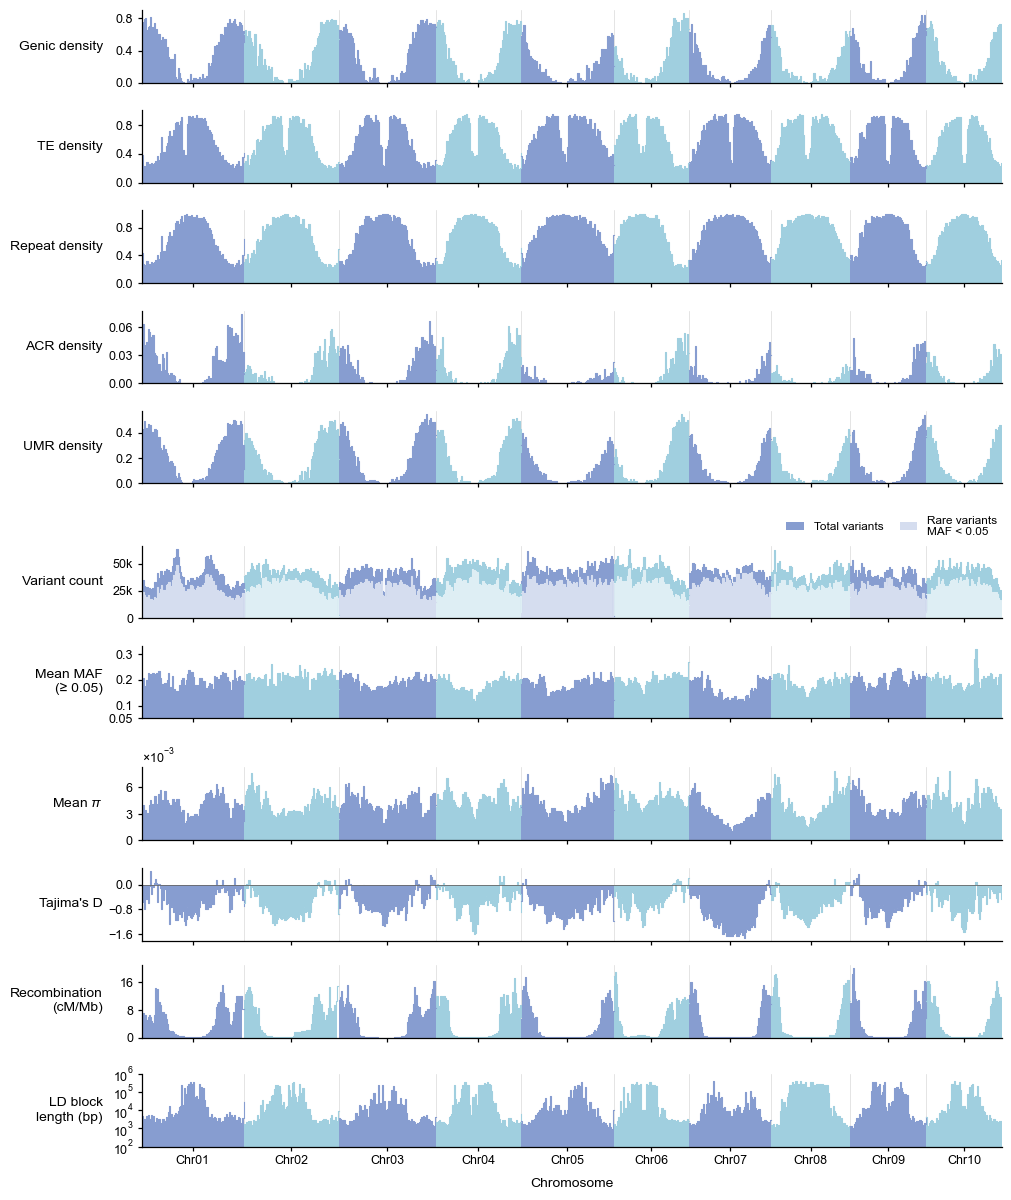

pdf: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.pdf
png: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.png
csv: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.csv.gz


In [14]:
import matplotlib.pyplot as plt
from src.contexts import plot_genome_tracks

track_df = pd.read_csv(track_data_csv)
plot_chromosomes = [f'Chr{i:02d}' for i in range(1, 11)]
track_df = track_df[track_df['CHROM'].isin(plot_chromosomes)].copy()
track_plot = plot_genome_tracks(
    track_df, output_prefix=track_output_prefix, rare_maf_threshold=rare_maf_threshold,
    maf_ymin=0.05, ld_ylim=(1e2, 1e6), figsize=(10, 12),
    hspace=0.1, h_pad=0.1, label_fontsize=10, tick_fontsize=9, title_fontsize=12,
)
track_fig, track_axes = track_plot['figure'], track_plot['axes']
track_plot_df = track_plot['plot_data']
plt.show()
for kind, file_path in track_plot['files'].items():
    print(f'{kind}: {file_path}')


### 1.3 Environmental characteristics of landraces

Describe the environments of landrace collection sites, their relationships with genotypic variation and correlations among environmental variables.


### 1.3 地方品种群体的环境特征

描述地方品种采集地的环境、环境与基因型变异的关系，以及环境变量之间的相关性。


#### Environmental variables

Variable descriptions, units and scaling factors define the environmental measurements associated with each collection site.


#### 环境变量

通过变量含义、单位和缩放系数，明确各采集地点所对应的环境测量值。


In [15]:
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
environment_ids = environment_metadata_df['env_id'].tolist()
key_environment_ids = ['gsl', 'bio18', 'al', 'striga']
landraces_env_df = landrace_metadata_df.set_index('LIB')[environment_ids].copy()
environment_metadata_df


,env_id,env_abbr,category,short description,description,source,units,scale,note,Reference DOI
0,bio1,TMA,Temperature,Mean.Tmp.Annual,Annual Mean Temperature,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
1,bio2,TRD,Temperature,Mean.Diurnal.Range,Mean Diurnal Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
2,bio3,ISO,Temperature,Isothermality,Isothermality,CHELSA V2.1,%,NaN,NaN,10.1038/sdata.2017.122
3,bio4,TSE,Temperature,Tmp.Seasonality,Temperature Seasonality,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
4,bio7,TAR,Temperature,Tmp.Annual.Range,Temperature Annual Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
5,bio8,TWQ,Temperature,Mean.Tmp.Wet.Q,Mean Temperature of Wettest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
6,bio9,TDQ,Temperature,Mean.Tmp.Dry.Q,Mean Temperature of Driest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
7,bio10,THQ,Temperature,Mean.Tmp.Warm.Q,Mean Temperature of Warmest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
8,bio11,TCQ,Temperature,Mean.Tmp.Cold.Q,Mean Temperature of Coldest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
9,bio15,PSE,Precipitation,Prec.Seasonality,Precipitation Seasonality,CHELSA V2.1,mm,10.0,NaN,10.1038/sdata.2017.122


#### Geographic distribution of key environments

Map `gsl`, `bio18`, `al` and `striga` at landrace collection sites. Color the genetic tree by `gsl` to compare environmental variation with genetic relationships. Values are displayed in the units defined for each variable; missing environmental values are gray.


#### 关键环境变量的地理分布

展示地方品种采集地的 `gsl`、`bio18`、`al` 和 `striga`。同时按 `gsl` 为遗传树着色，对照环境变化与遗传关系。数值采用各变量定义的单位显示；缺少环境值的样本以灰色表示。


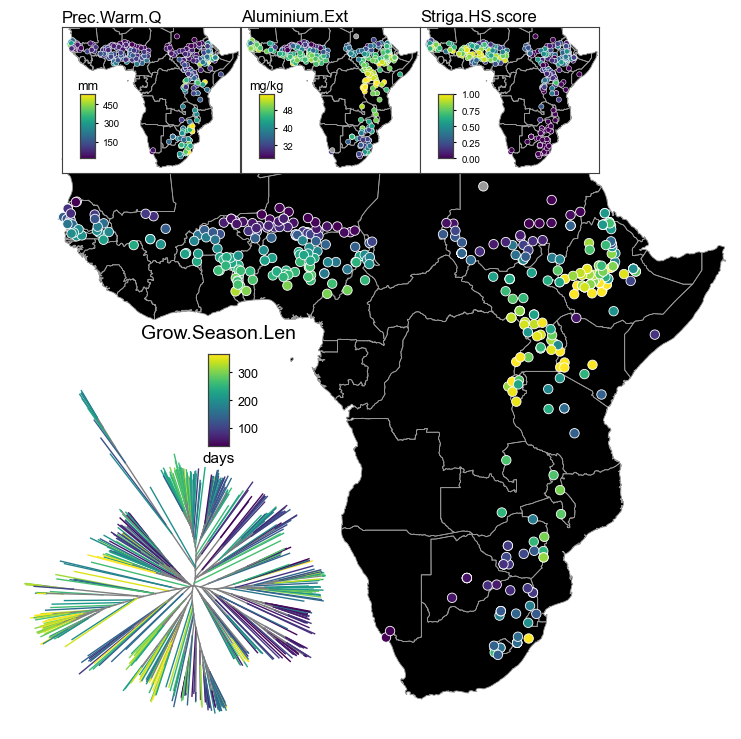

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_env_vars_map.fig1.pdf


In [16]:
import matplotlib.pyplot as plt
from src.env_vars import env_vars_map_plotter

main_env = key_environment_ids[0]
small_envs = key_environment_ids[1:]
longitude_limit = (-20, 52)
latitude_limit = (-37, 22)
world_map_shp = f'{source_dir}/natural_earth/ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp'
save_fig_path = f'{results_dir}/landraces_env_vars_map.fig1.pdf'

environment_map_fig, environment_map_ax = env_vars_map_plotter(
    main_env, small_envs, landrace_metadata_df, nj_tree_file,
    environment_metadata_df, save_fig_path, world_map_shp,
    longitude_limit=longitude_limit, latitude_limit=latitude_limit,
)
plt.show()
print(f'Figure: {save_fig_path}')


#### Environmental relationships with genotypic variation

Use redundancy analysis (RDA) to summarize genotypic variation associated with the environmental variables. Analyze LD-pruned variants in samples with complete environmental profiles, standardizing environmental variables to account for their different scales. Adjusted R² summarizes the fraction of genotypic variation explained by the model.


#### 环境与基因型变异的关系

使用冗余分析（RDA）概括与环境变量相关的基因型变异。对环境信息完整的样本，使用经过 LD pruning 的变异进行分析，并标准化环境变量以消除量纲差异。调整后的 R² 概括模型解释的基因型变异比例。


In [17]:
from src.env_vars import rda_analysis

rda_output_dir = f'{results_dir}/RDA'
rda_samples_csv = f'{rda_output_dir}/rda_samples.csv'
rda_env_contrib_csv = f'{rda_output_dir}/rda_env_contrib.csv'
rda_explained_csv = f'{rda_output_dir}/rda_explained.csv'
rda_result_files = [rda_samples_csv, rda_env_contrib_csv, rda_explained_csv]

stage_start = perf_counter()
if all(os.path.exists(file_path) for file_path in rda_result_files):
    print(f'[{datetime.now():%H:%M:%S}] Reusing RDA results: {rda_output_dir}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating environmental RDA', flush=True)
    rda_analysis(
        vcf=snp_pruned_vcf_file, landraces_env_df=landraces_env_df,
        kinship_file=f'{nj_prefix}.ibs.matrix', output_dir=rda_output_dir,
    )
rda_explained_df = pd.read_csv(rda_explained_csv, index_col=0)
r2_adj = rda_explained_df.loc[rda_explained_df['RDA'] == 'R2_adj', 'explained_variance'].iloc[0]
print(f'Adjusted R-squared: {r2_adj:.4f}')
print(f'[{datetime.now():%H:%M:%S}] RDA results ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:35:00] Reusing RDA results: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/RDA
Adjusted R-squared: 0.2002
[04:35:00] RDA results ready (0.0 s)


##### Plot the RDA biplot

Show samples on the first two RDA axes and environmental vectors indicating their correlations with these axes. Red outlines mark `gsl`, `bio18`, `al` and `striga`, the four key variables used in subsequent analyses.


##### 绘制 RDA 双标图

展示样本在前两个 RDA 轴上的分布；环境变量箭头表示其与这两个轴的相关性。红框标出后续分析使用的四个关键变量：`gsl`、`bio18`、`al` 和 `striga`。


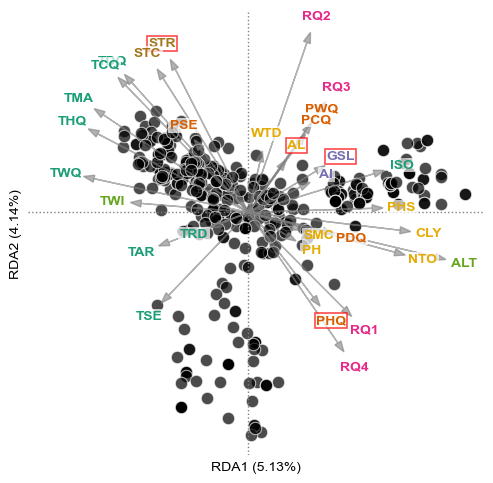

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_env_rda.fig1.pdf


In [18]:
import matplotlib.pyplot as plt
from src.env_vars import plot_rda_biplot

rda_samples_df = pd.read_csv(rda_samples_csv, index_col=0)
rda_env_contrib_df = pd.read_csv(rda_env_contrib_csv, index_col=0)
rda_explained_df = pd.read_csv(rda_explained_csv, index_col=0)
save_fig_path = f'{results_dir}/landraces_env_rda.fig1.pdf'
rda_fig, rda_ax = plot_rda_biplot(
    rda_samples_df, rda_env_contrib_df, rda_explained_df, environment_metadata_df,
    save_fig_path, highlight_env_ids=key_environment_ids,
)
plt.show()
print(f'Figure: {save_fig_path}')


#### Correlations among environmental variables

Calculate Pearson correlations among environmental variables using samples with complete environmental profiles to describe their shared variation.


#### 环境变量之间的相关性

使用环境信息完整的样本，计算环境变量之间的 Pearson 相关系数，描述它们的共同变化。


In [19]:
# ai done: calculate-environment-correlations

correlation_csv = f'{results_dir}/env_correlation_matrix.csv'
if os.path.exists(correlation_csv):
    environmental_corr_df = pd.read_csv(correlation_csv, index_col=0)
    print(f'Reusing environmental correlations: {correlation_csv}')
else:
    environmental_corr_df = landraces_env_df.dropna().corr(method='pearson')
    environmental_corr_df.to_csv(correlation_csv)
print(f'Environmental variables: {len(environmental_corr_df):,}')

Reusing environmental correlations: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/env_correlation_matrix.csv
Environmental variables: 31


##### Plot the environmental correlation network

Connect variable pairs with absolute Pearson r ≥0.7. Edge colors distinguish positive and negative correlations; circle sizes in the main connected component reflect the number of connections. Thick red outlines highlight `gsl`, `bio18`, `al` and `striga`.


##### 绘制环境相关网络

连接绝对 Pearson 相关系数 ≥0.7 的变量对。连线颜色区分正、负相关，主连通网络的圆圈大小反映连接数量。红色加粗外边线突出 `gsl`、`bio18`、`al` 和 `striga`。


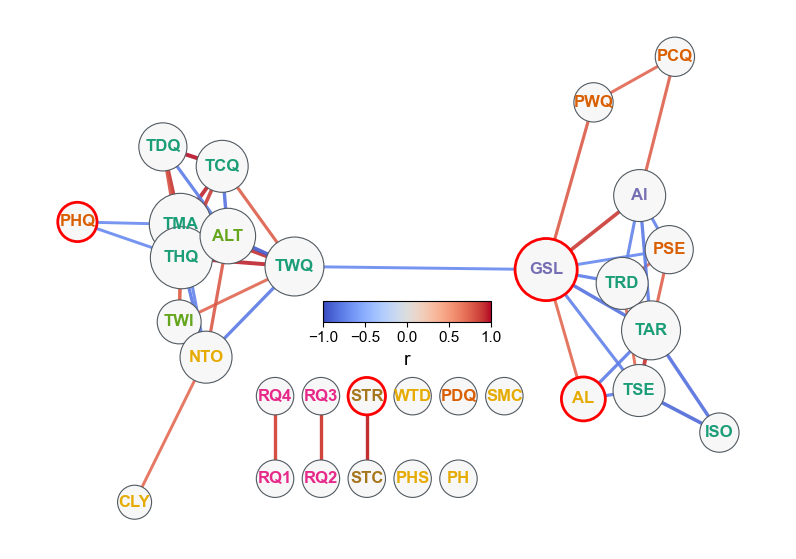

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/env_network_custom_layout.fig1.pdf


In [20]:
# ai done: plot-environment-correlation-network

import matplotlib.pyplot as plt
from src.env_vars import plot_env_corr_network

environmental_corr_df = pd.read_csv(correlation_csv, index_col=0)
correlation_threshold = 0.7
save_fig_path = f'{results_dir}/env_network_custom_layout.fig1.pdf'
environment_network_fig, environment_network_ax = plot_env_corr_network(
    environment_metadata_df, landraces_env_df, r_threshold=correlation_threshold,
    save_fig_path=save_fig_path, highlight_env_ids=key_environment_ids,
    correlation_df=environmental_corr_df,
)
plt.show()
print(f'Figure: {save_fig_path}')


## 2. Environmental GWAS

Treat environmental measurements at collection sites as phenotypes to identify associated genetic variants. GEMMA uses a linear mixed model with the IBS relatedness matrix; MAGMA aggregates site associations into gene-level signals.


## 2. 环境 GWAS

以采集地点的环境测量值为表型，识别与环境相关的遗传变异。GEMMA 使用包含 IBS 亲缘关系矩阵的线性混合模型；MAGMA 将位点关联汇总为基因层面的信号。


### 2.1 Prepare association inputs

Use the genome-wide QC variants (MAF ≥0.05) and CDS variants (MAF ≥0.01), together with the IBS matrix calculated from LD-pruned SNPs. Align environmental measurements and genotypes by sample identity; samples lacking a particular environmental measurement are excluded from that variable’s association test.


### 2.1 准备关联分析输入

使用全基因组质控变异（MAF ≥0.05）和 CDS 变异（MAF ≥0.01），以及基于 LD-pruned SNP 计算的 IBS 矩阵。按样本身份对齐环境测量值和基因型；缺少某个环境测量值的样本不参与该变量的关联检验。


In [21]:
from src.gwas import GEMMA_JOB, MAGMA_JOB, prepare_gemma_phenotype_file
from src.vcf import get_sample_list_from_vcf
from tqdm.auto import tqdm

genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_cds_vcf_file = f'{results_dir}/landraces_cds_maf0.01_het0.05.vcf.gz'
ibs_matrix_file = f'{kinship_result_prefix}.ibs.matrix'
gwas_dir = f'{results_dir}/gwas'
gwas_workers = project_config['resources']['environmental_gwas']['cores']
magma_workers = project_config['resources']['environmental_gwas']['cores']
gwas_memory_gb = project_config['resources']['environmental_gwas']['memory_gb']
plink_threads = project_config['resources']['interactive']['cores']
gemma_block_size = 5_000_000
gemma_lmm = 4
plink_memory_mb = 16000
os.makedirs(gwas_dir, exist_ok=True)

# BIMBAM phenotypes and IBS rows must follow the genotype sample order.
gwas_sample_ids = get_sample_list_from_vcf(landraces_qc_vcf_file)
if gwas_sample_ids != get_sample_list_from_vcf(landraces_cds_vcf_file):
    raise ValueError('Genome and CDS VCF sample orders differ.')
if gwas_sample_ids != get_sample_list_from_vcf(snp_pruned_vcf_file):
    raise ValueError('GWAS VCF and IBS-source VCF sample orders differ.')
if landrace_metadata_df['LIB'].duplicated().any():
    raise ValueError('Landrace metadata contains duplicate sample IDs.')
gwas_phenotype_df = landrace_metadata_df.set_index('LIB').loc[gwas_sample_ids, environment_ids]

envGWAS_job_dict = {}
for env_name in tqdm(environment_ids, desc='Preparing environmental GWAS', unit='variable'):
    env_job_dir = f'{gwas_dir}/{env_name}'
    os.makedirs(env_job_dir, exist_ok=True)
    pheno_file = prepare_gemma_phenotype_file(env_name, gwas_phenotype_df, f'{env_job_dir}/pheno.bimbam')
    envGWAS_job_dict[env_name] = {
        'site': GEMMA_JOB(env_name, env_job_dir, landraces_qc_vcf_file, pheno_file, ibs_matrix_file, lmm=gemma_lmm),
        'gene': MAGMA_JOB(
            env_name, env_job_dir, landraces_qc_vcf_file, gff_file,
            site_gwas_df_h5=f'{env_job_dir}/{env_name}.gemma/{env_name}.gemma.gwas_df.h5',
            phenotype_file=pheno_file, threads=plink_threads, memory_mb=plink_memory_mb, max_workers=magma_workers,
        ),
        'cds': GEMMA_JOB(f'{env_name}_cds', env_job_dir, landraces_cds_vcf_file, pheno_file, ibs_matrix_file, lmm=gemma_lmm),
    }
print(f'Prepared {len(envGWAS_job_dict):,} variables; samples: {len(gwas_sample_ids):,}')
print(f'GEMMA process limit: {gwas_workers}; total memory budget: {gwas_memory_gb} GB (not a hard limit)')
print(f'MAGMA batch process limit: {magma_workers}; environmental variables run sequentially')


Preparing environmental GWAS: 100%|██████████| 31/31 [00:00<00:00, 774.56variable/s]

Prepared 31 variables; samples: 443
GEMMA process limit: 80; total memory budget: 500 GB (not a hard limit)
MAGMA batch process limit: 80; environmental variables run sequentially


### 2.2 Genome-wide variant associations

Test each environmental variable against genome-wide variants using GEMMA. Use Wald-test P values and control the false discovery rate across tested variants with the Benjamini–Hochberg procedure.


### 2.2 全基因组变异关联

使用 GEMMA 检验各环境变量与全基因组变异的关联。采用 Wald 检验 P 值，并通过 Benjamini–Hochberg 方法控制受检变异的假发现率。


In [22]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting genome-wide GEMMA with up to {gwas_workers} single-threaded workers; total memory budget {gwas_memory_gb} GB', flush=True)
for env_name in tqdm(environment_ids, desc='Genome-wide GEMMA', unit='variable'):
    site_job = envGWAS_job_dict[env_name]['site']
    site_job.run(block_size=gemma_block_size, max_workers=gwas_workers)
    if not os.path.exists(site_job.gwas_df_h5):
        raise RuntimeError(f'GEMMA result is incomplete: {site_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] Genome-wide associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:35:02] Starting genome-wide GEMMA with up to 80 single-threaded workers; total memory budget 500 GB


Genome-wide GEMMA: 100%|██████████| 31/31 [00:00<00:00, 1819.86variable/s]

GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS res

### 2.3 Gene-level associations

Use MAGMA to combine variant associations within genes and their 2 kb flanks while accounting for LD. Summarize gene-level associations for the four key environmental variables, using the number of landraces included in each GWAS as its sample size.


### 2.3 基因层面的关联

使用 MAGMA 汇总基因及两侧各 2 kb 范围内的变异关联，并考虑 LD，概括四个重点环境变量的基因层面关联。各变量的样本量采用其 GWAS 实际纳入的地方品种数量。


In [23]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting MAGMA gene associations', flush=True)
for env_name in tqdm(key_environment_ids, desc='MAGMA gene associations', unit='variable'):
    site_job = envGWAS_job_dict[env_name]['site']
    if not os.path.exists(site_job.gwas_df_h5):
        raise RuntimeError(f'Run genome-wide GEMMA first: {site_job.gwas_df_h5}')
    gene_job = envGWAS_job_dict[env_name]['gene']
    gene_job.run()
    if not os.path.exists(gene_job.gwas_df_h5):
        raise RuntimeError(f'MAGMA result is incomplete: {gene_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] Gene associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:35:03] Starting MAGMA gene associations


MAGMA gene associations:   0%|          | 0/4 [00:00<?, ?variable/s]

gsl: MAGMA GWAS sample size N=442; LD-reference samples=443
MAGMA GWAS result already exists.
bio18: MAGMA GWAS sample size N=443; LD-reference samples=443
MAGMA GWAS result already exists.
al: MAGMA GWAS sample size N=437; LD-reference samples=443
MAGMA GWAS result already exists.
striga: MAGMA GWAS sample size N=440; LD-reference samples=443


MAGMA gene associations: 100%|██████████| 4/4 [00:00<00:00, 78.68variable/s]

MAGMA GWAS result already exists.
[04:35:03] Gene associations ready (0.1 s)


### 2.4 Coding-variant associations

Test the CDS variant panel separately to examine environmental associations involving coding variation, including variants retained by its lower MAF cutoff.


### 2.4 编码变异关联

对 CDS 变异数据单独检验，考察涉及编码区变异的环境关联，包括较低 MAF 阈值保留的变异。


In [24]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting CDS GEMMA with up to {gwas_workers} single-threaded workers; total memory budget {gwas_memory_gb} GB', flush=True)
for env_name in tqdm(environment_ids, desc='CDS GEMMA', unit='variable'):
    cds_job = envGWAS_job_dict[env_name]['cds']
    cds_job.run(block_size=gemma_block_size, max_workers=gwas_workers)
    if not os.path.exists(cds_job.gwas_df_h5):
        raise RuntimeError(f'CDS GEMMA result is incomplete: {cds_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] CDS associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[04:35:03] Starting CDS GEMMA with up to 80 single-threaded workers; total memory budget 500 GB


CDS GEMMA: 100%|██████████| 31/31 [00:00<00:00, 2119.79variable/s]

GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS result already exists.
GEMMA GWAS res

### 2.5 Inspect association patterns

Use Manhattan plots to locate genome-wide association signals, QQ plots to compare observed and expected P values, and histograms to inspect their distribution. The Manhattan panels display an FDR threshold of 0.05.


### 2.5 查看关联模式

通过 Manhattan 图定位全基因组关联信号，通过 QQ 图比较观测与预期 P 值，并通过直方图查看 P 值分布。Manhattan 图显示 FDR 0.05 的阈值。


In [25]:
import matplotlib.pyplot as plt
from src.gwas import plot_gwas_summary_panel

gwas_fdr_threshold = 0.05
gwas_histogram_bins = 50
gwas_plot_force_recompute = False
environment_descriptions = environment_metadata_df.set_index('env_id')['description'].to_dict()
for env_name in tqdm(environment_ids, desc='Plotting GWAS summaries', unit='variable'):
    gwas_result_h5 = f'{gwas_dir}/{env_name}/{env_name}.gemma/{env_name}.gemma.gwas_df.h5'
    gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
    gwas_pdf = gwas_result_h5.replace('.h5', '_gwas_summary.pdf')
    gwas_plot_csv = gwas_result_h5.replace('.h5', '_gwas_summary.csv.gz')
    if gwas_plot_force_recompute or not all(os.path.exists(file_path) for file_path in [gwas_png, gwas_pdf, gwas_plot_csv]):
        summary_fig, summary_axes = plot_gwas_summary_panel(
            gwas_result_h5, genome_fasta_file, threshold_fdr=gwas_fdr_threshold,
            bins=gwas_histogram_bins, title=environment_descriptions[env_name], save=True,
        )
        plt.close(summary_fig)
print(f'GWAS summaries: {gwas_dir}')


Plotting GWAS summaries: 100%|██████████| 31/31 [00:00<00:00, 19638.03variable/s]

GWAS summaries: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/gwas


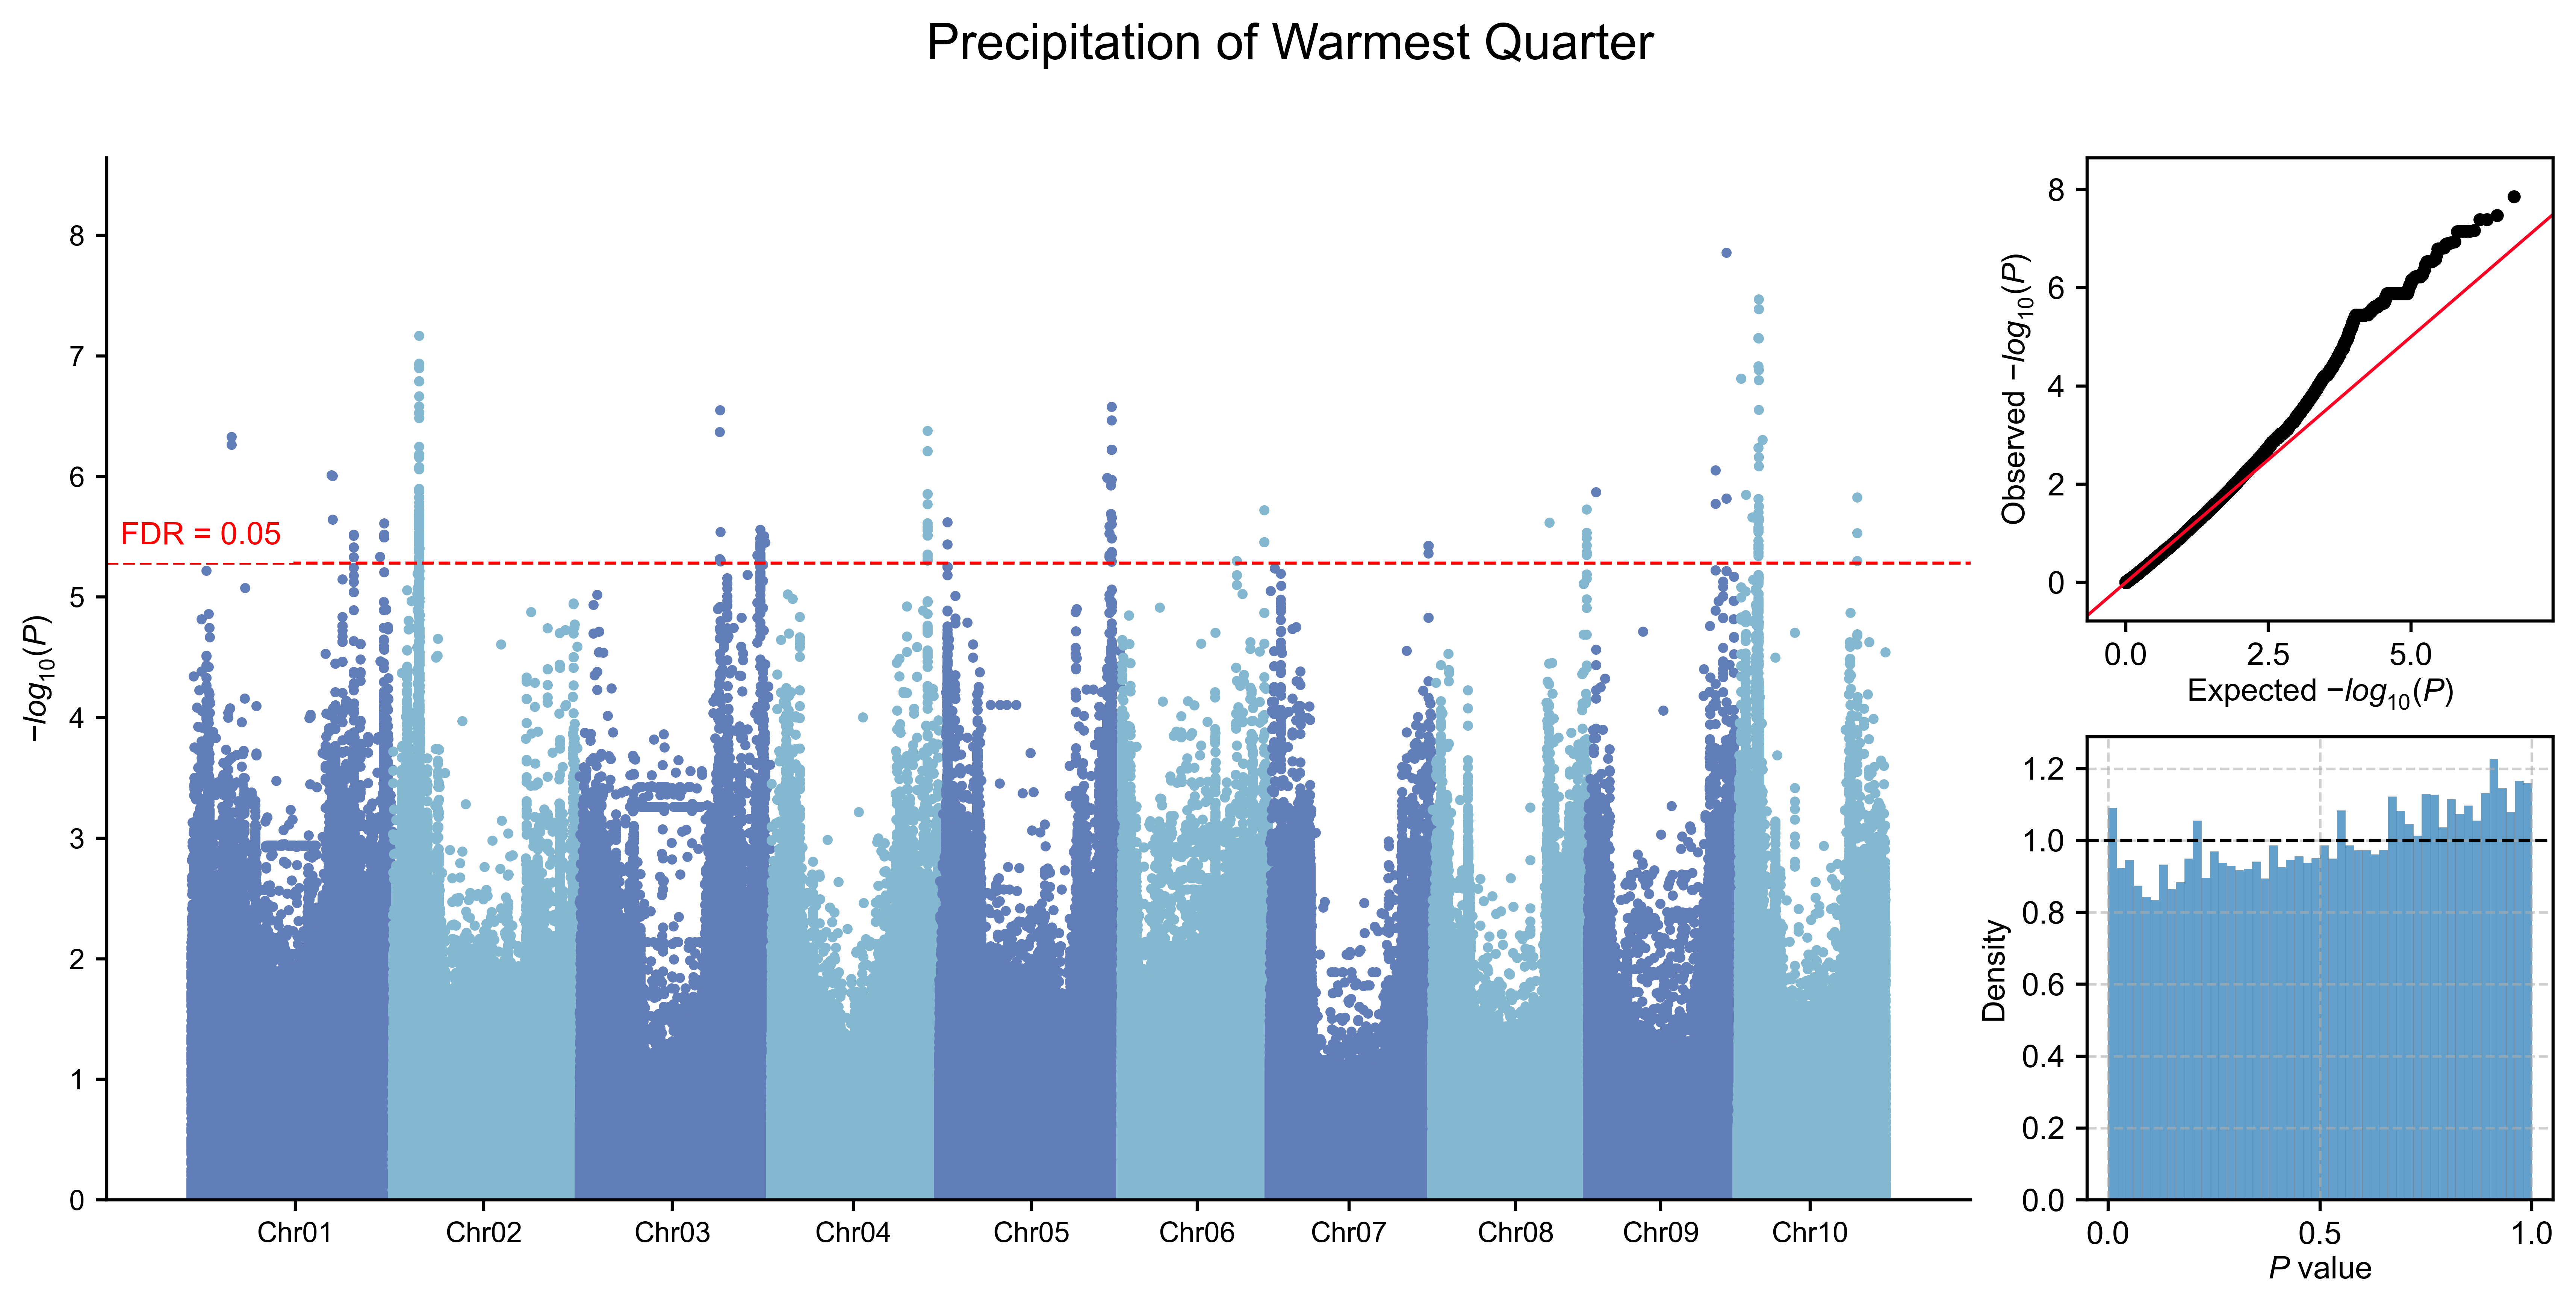

In [26]:
from IPython.display import Image, display

env_id = 'bio18'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


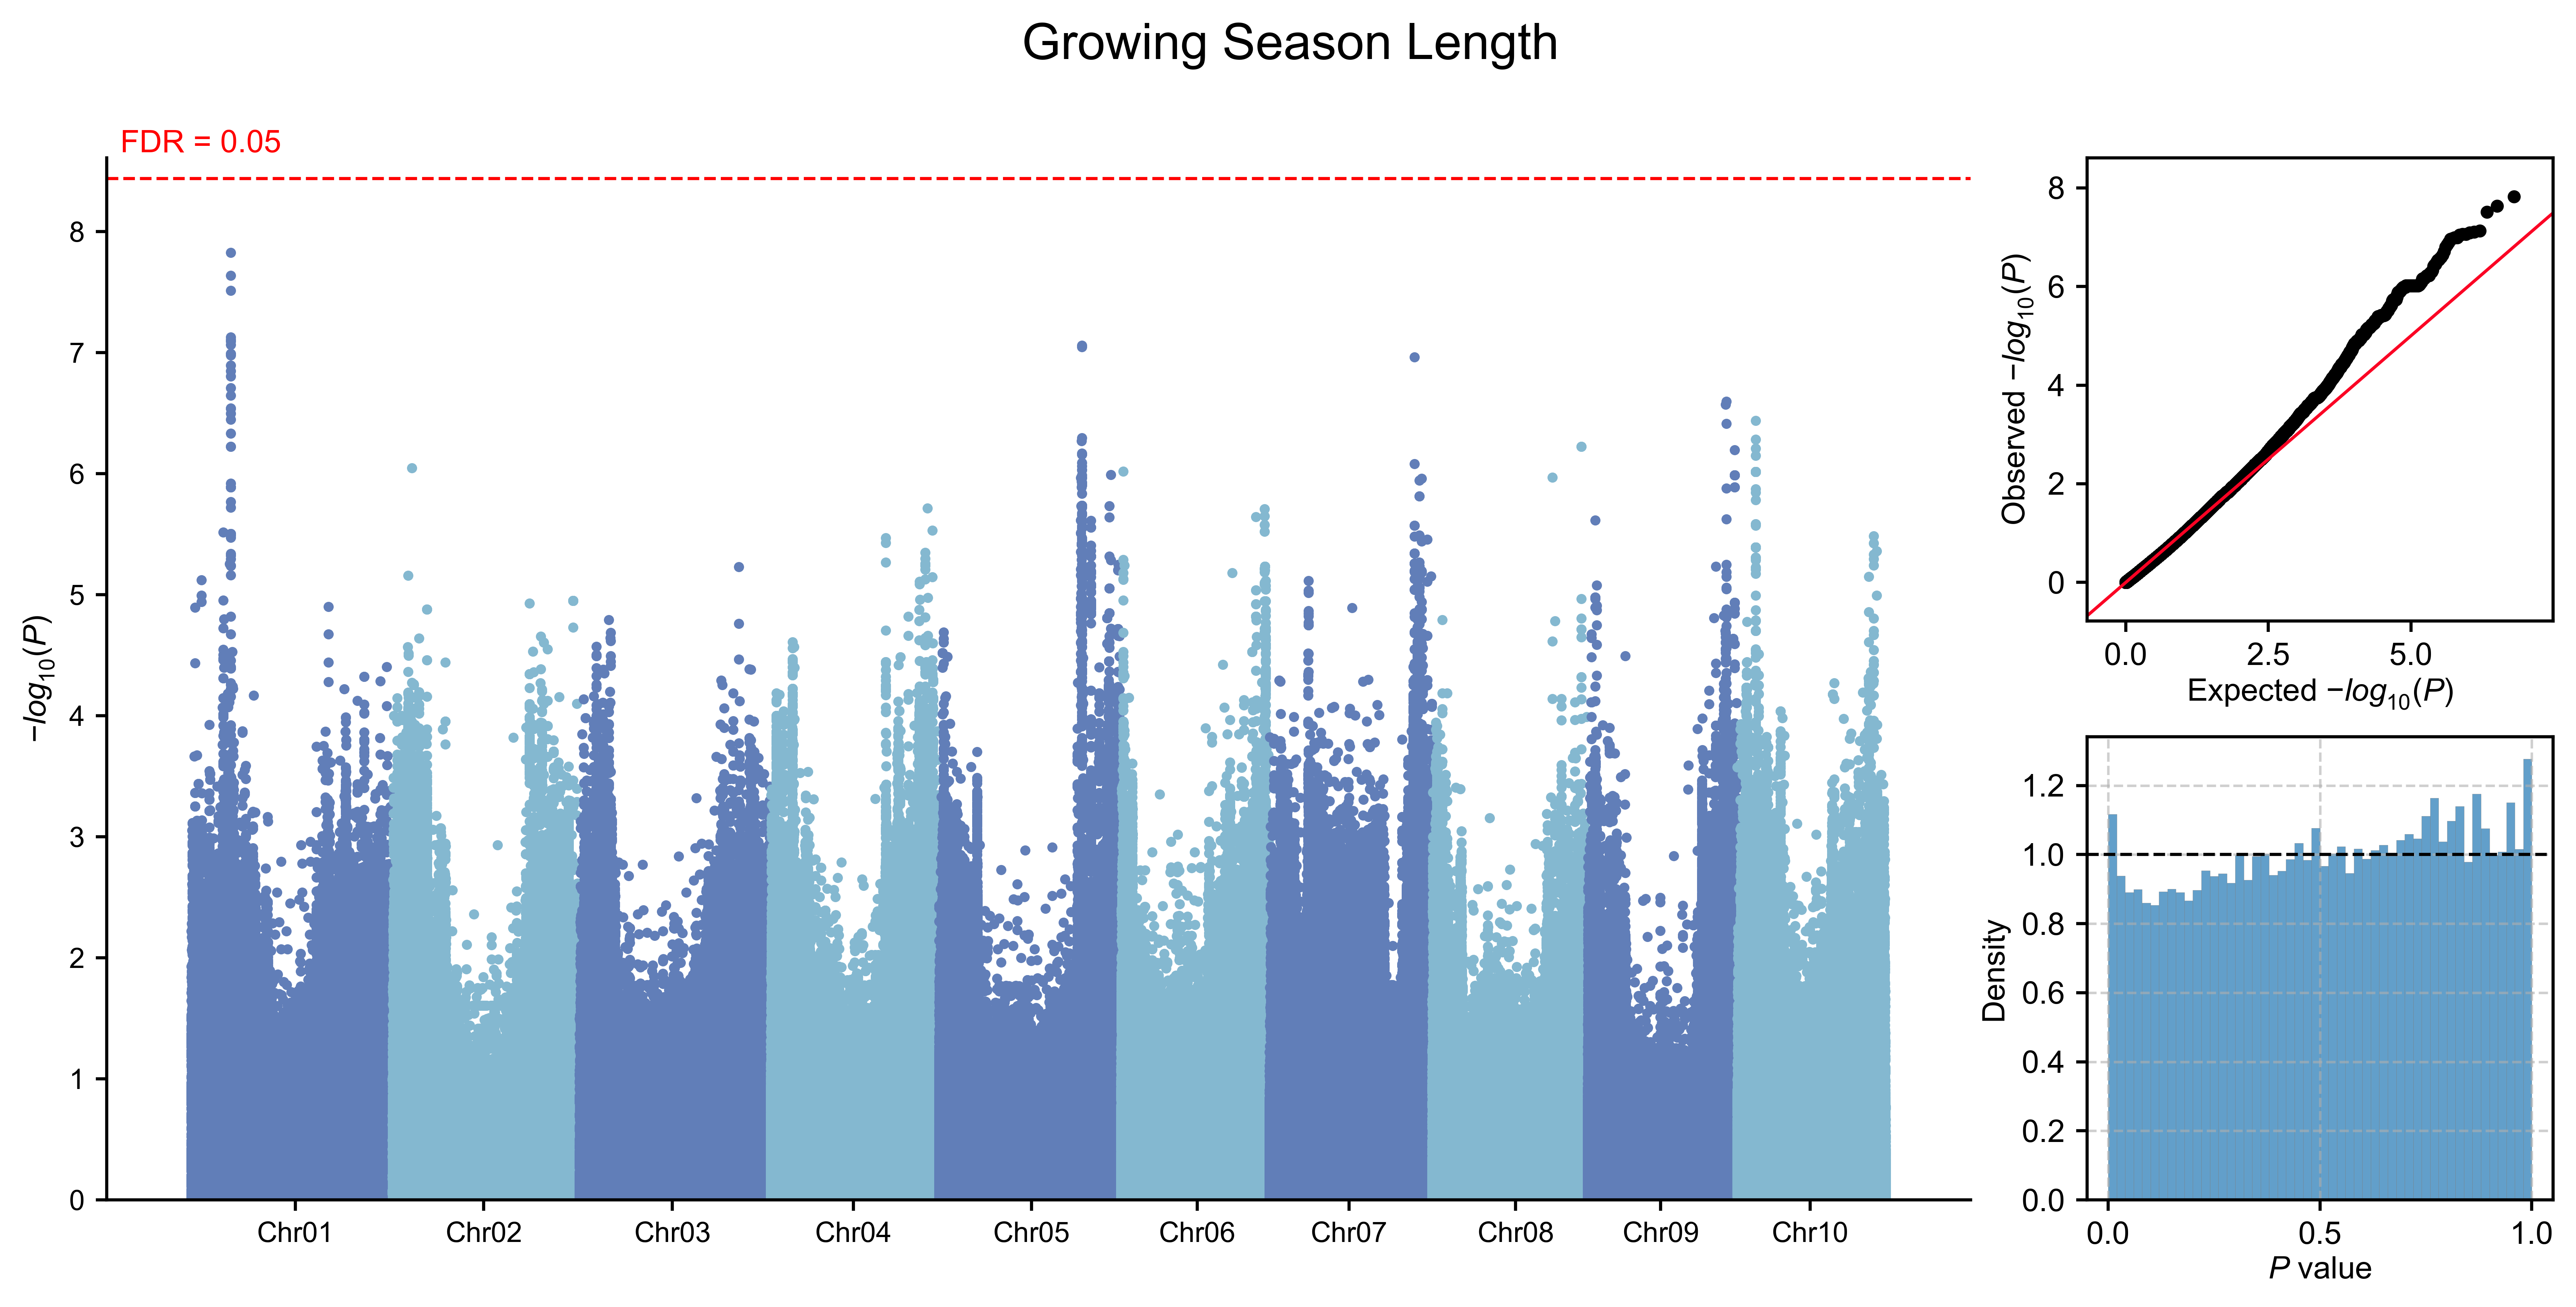

In [27]:
from IPython.display import Image, display

env_id = 'gsl'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


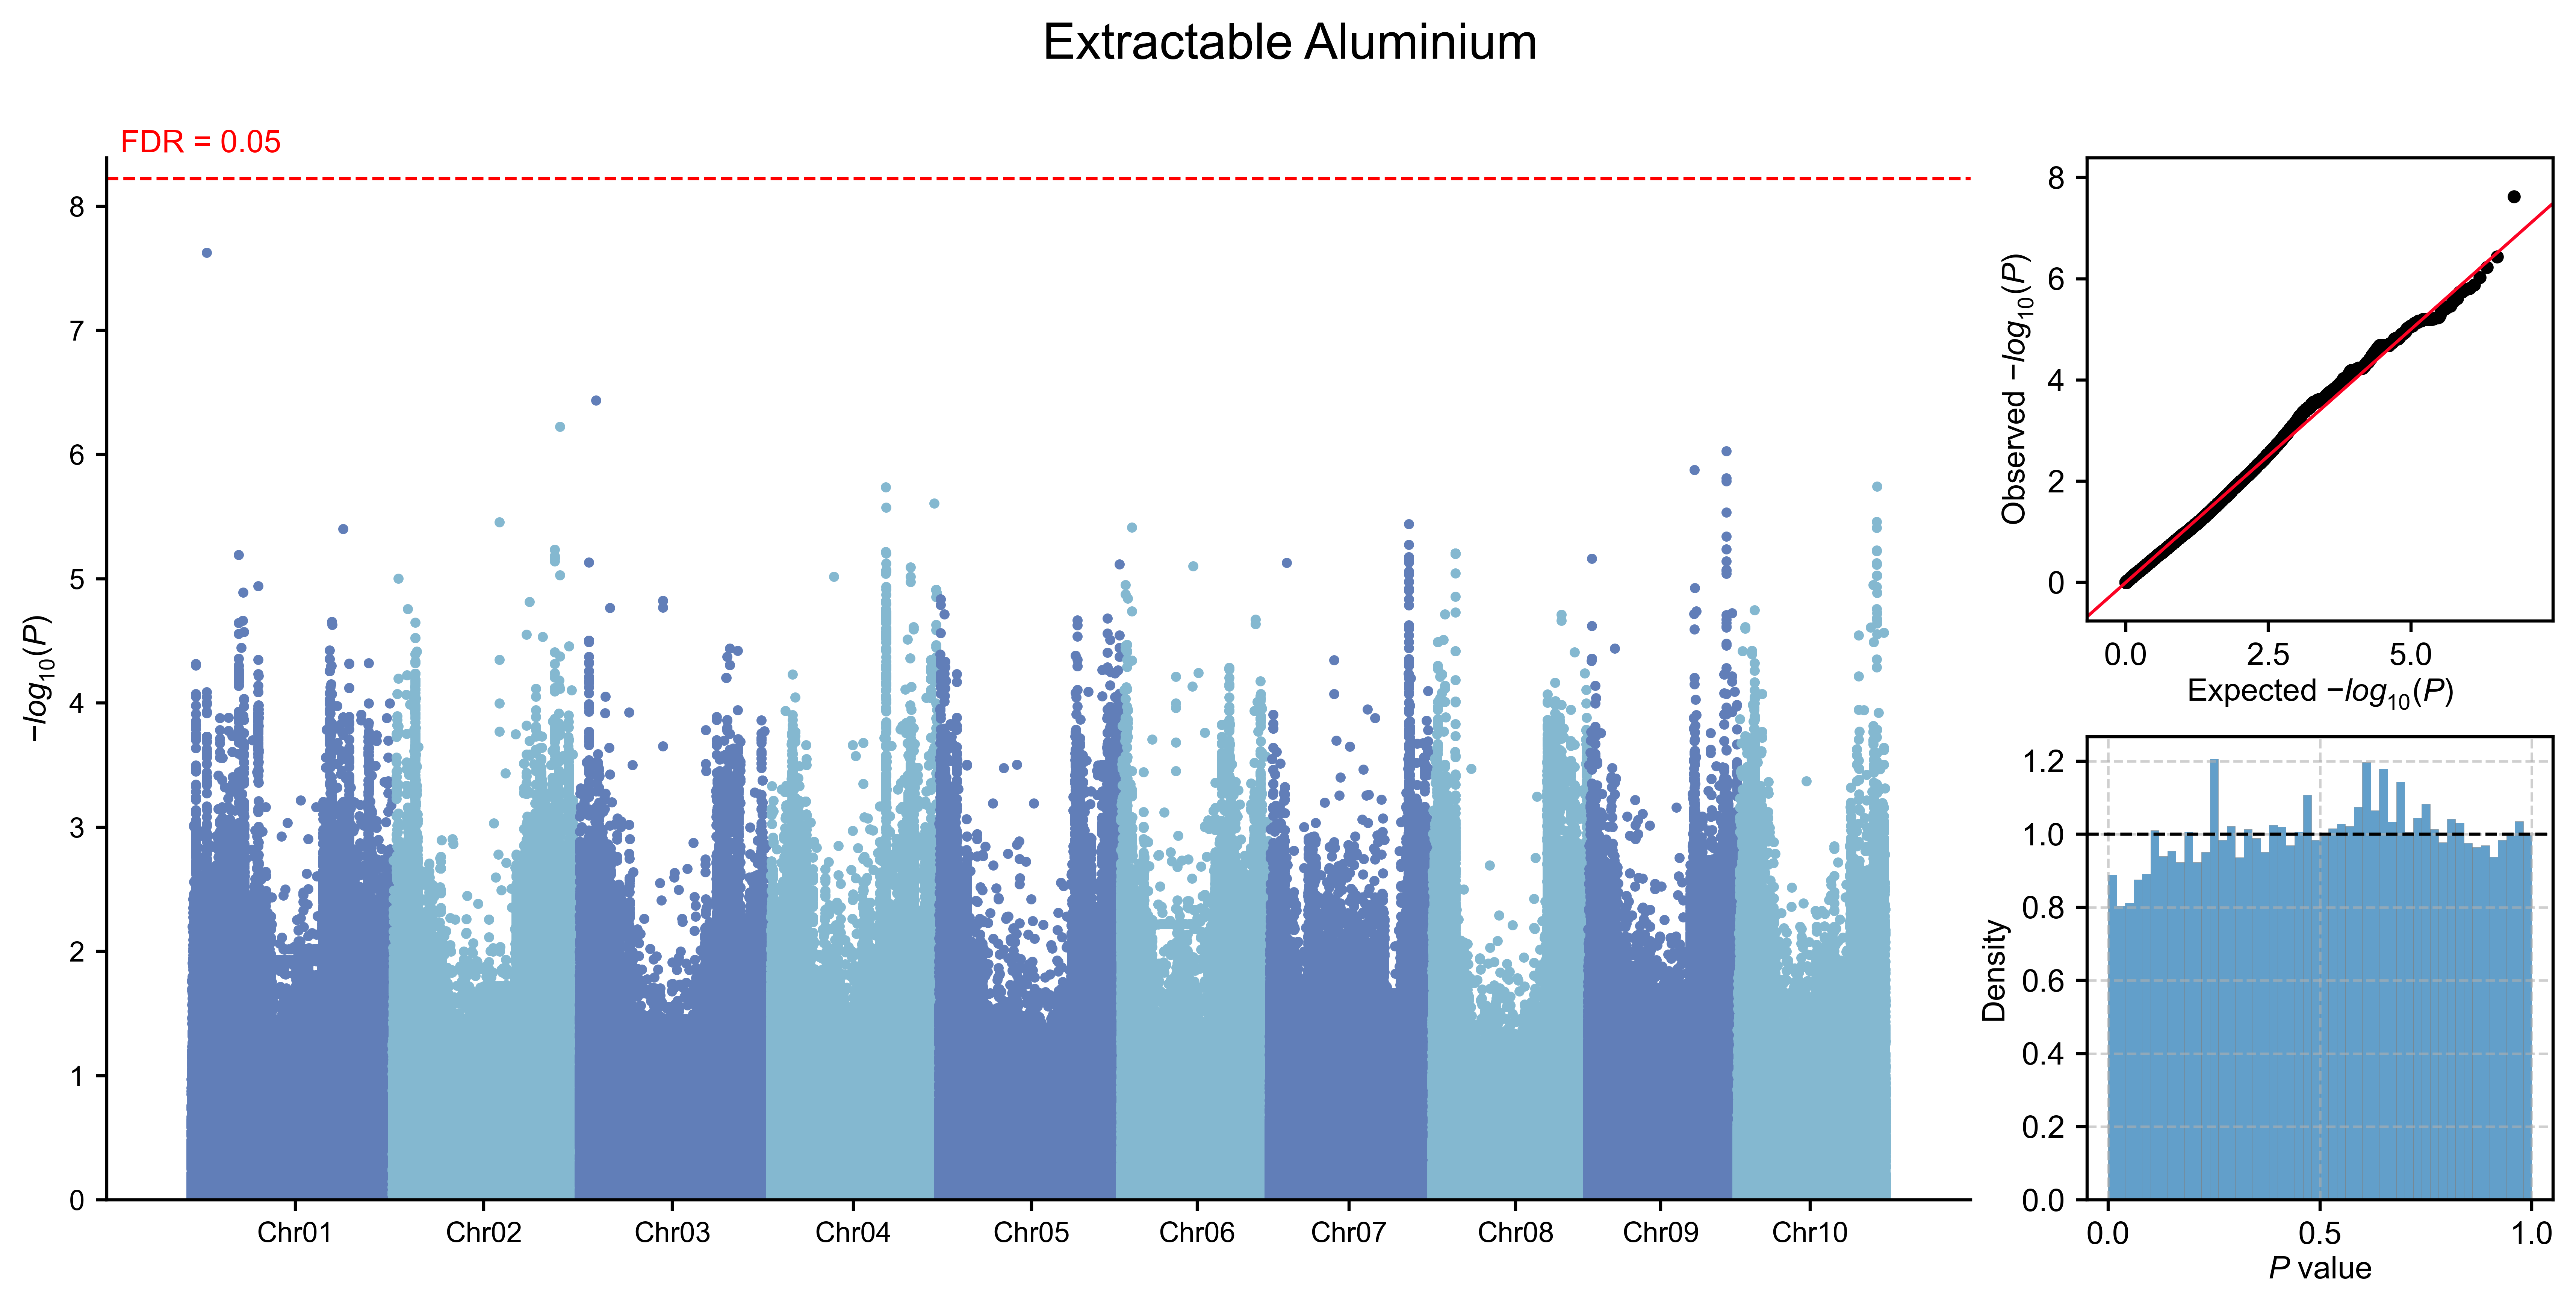

In [28]:
from IPython.display import Image, display

env_id = 'al'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


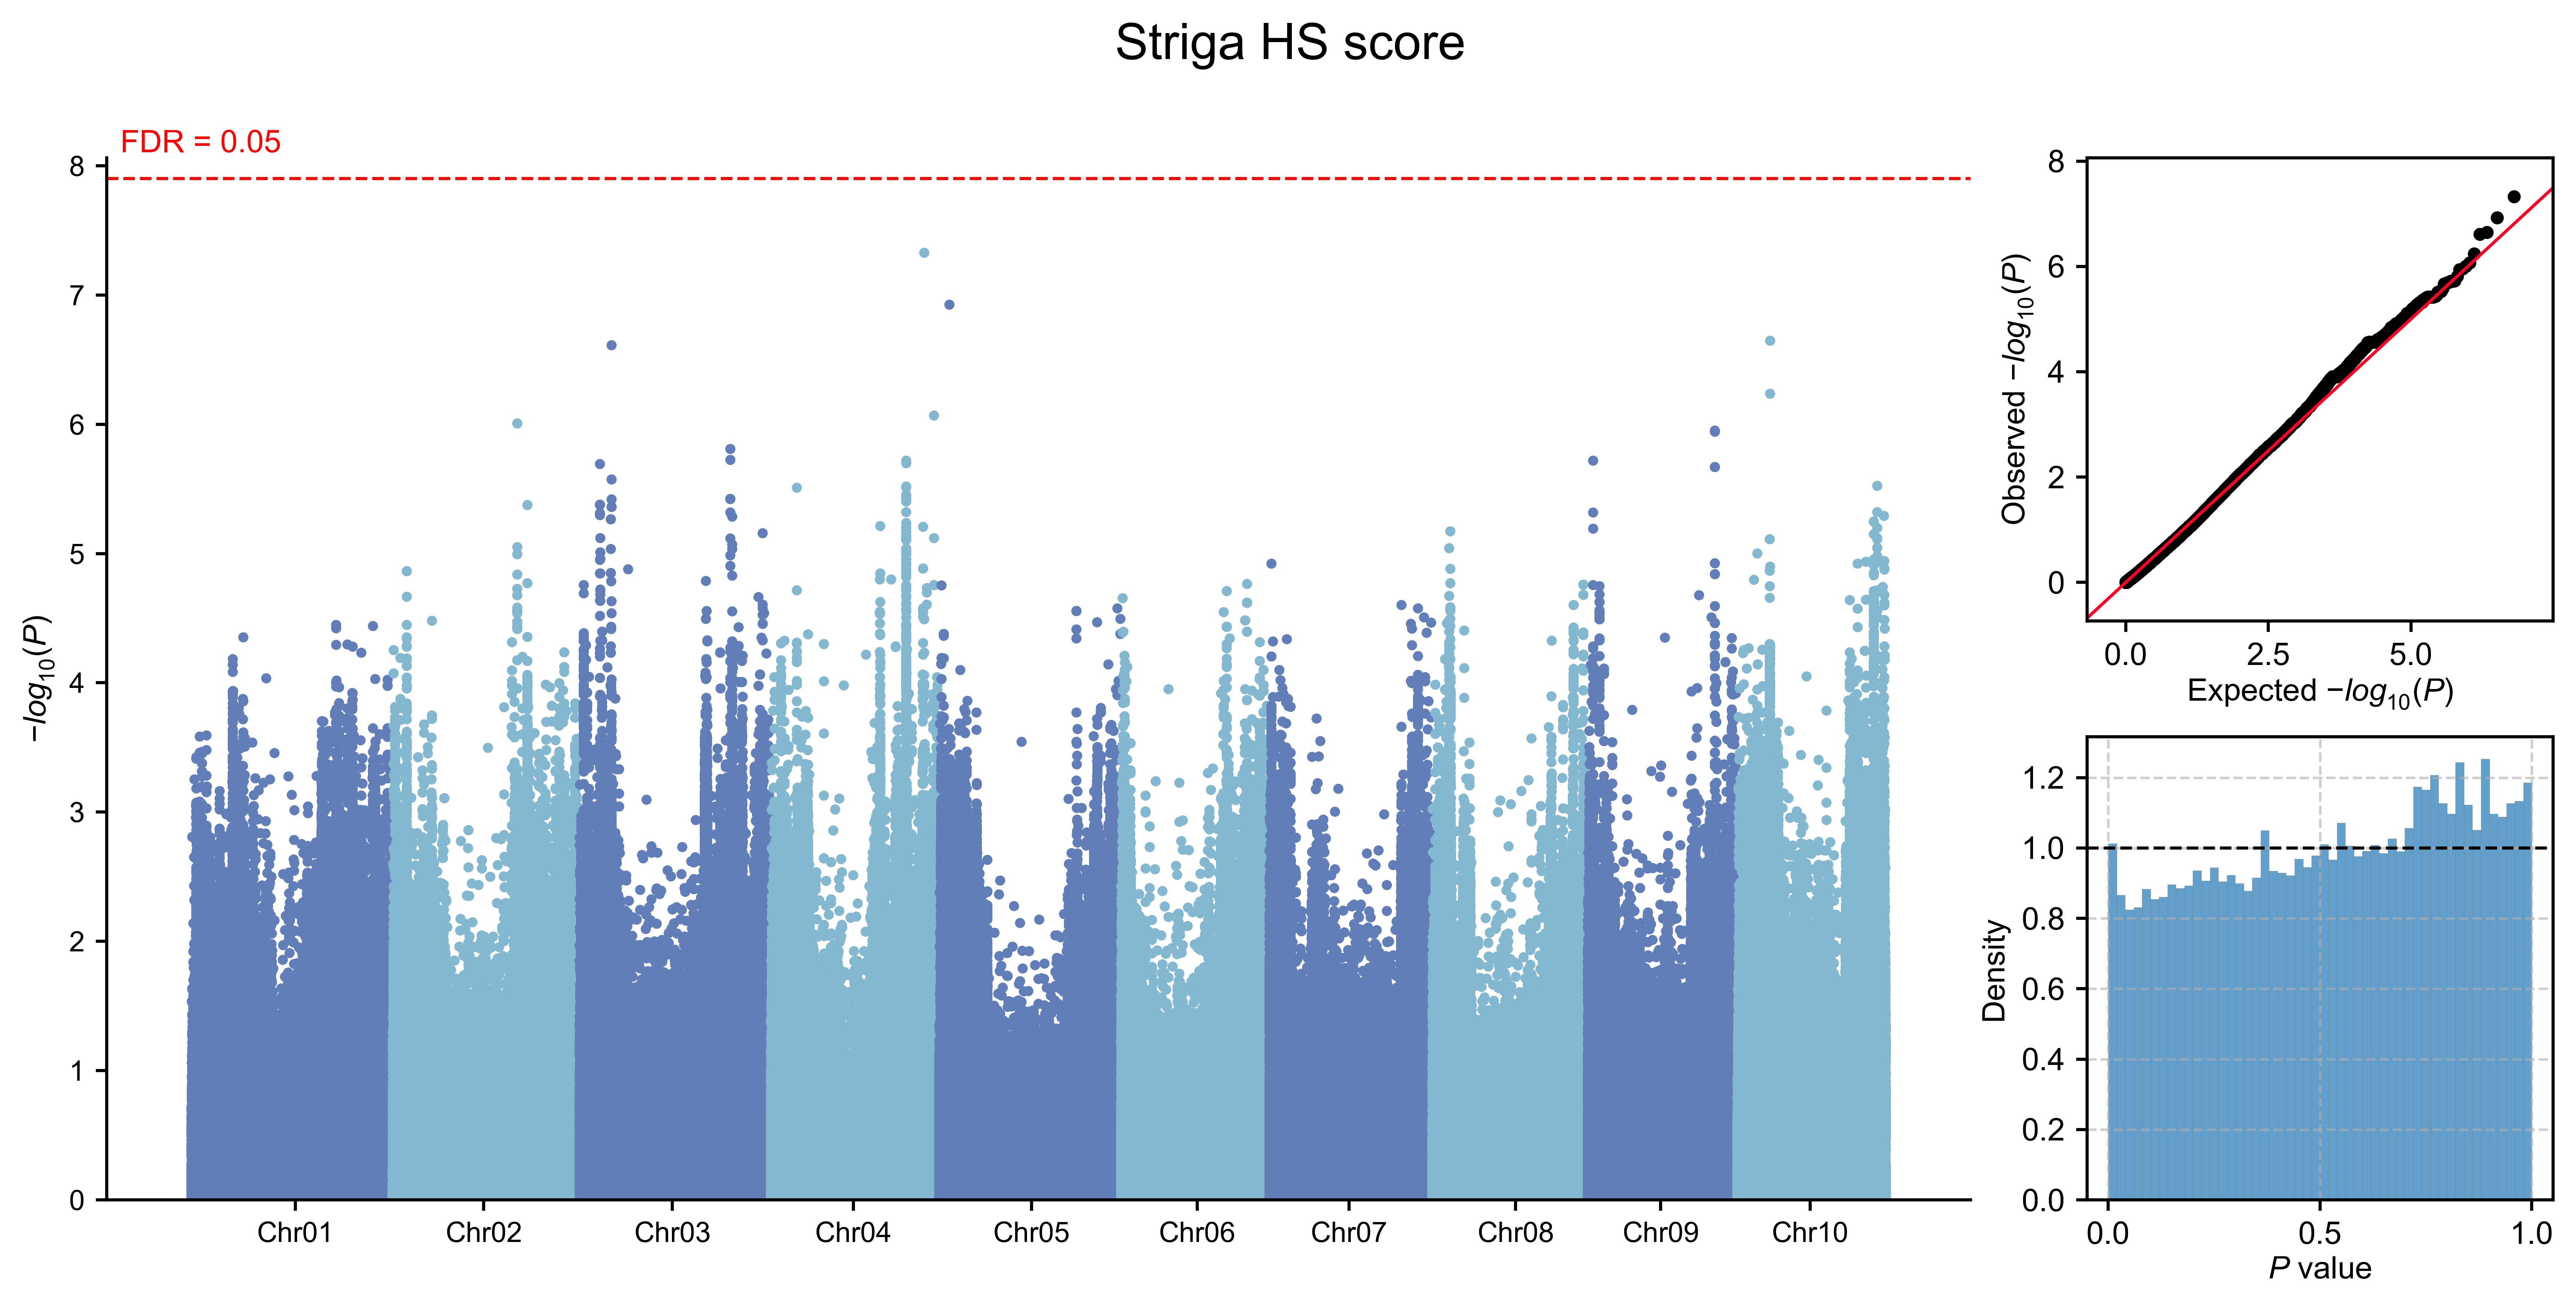

In [29]:
from IPython.display import Image, display

env_id = 'striga'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


## 3. Genomic feature and GEA landscapes

Compare genomic features with environmental association signals in aligned 1 Mb windows across Chr01–Chr10. The main figure displays genomic and epigenomic coverage, gene expression, co-expression networks and riboSNitches; the supplementary figure displays recombination, population-genetic variation and phylogenetic conservation. Both figures share the environmental tree and cloned flowering-gene markers.


## 3. 基因组特征与GEA信号的全基因组分布

在Chr01–Chr10对齐的1 Mb窗口中，比较基因组特征与环境关联信号。主图展示基因组与表观基因组覆盖、基因表达、共表达网络和riboSNitch；附图展示重组率、群体遗传变异和系统发育保守性。两图共用环境变量聚类树和已克隆开花基因标记。


### 3.1 Genomic feature summaries

Genic coverage includes gene bodies and 2 kb flanks; TE, ACR and UMR tracks use the existing interval-union coverage fractions. Gene categories are counted by gene midpoint, and riboSNitches are counted among genome-wide QC variants. Conservation categories are counted within genes and their 15 kb flanks; Non-evaluable includes sites without conservation information.

Population tracks follow Section 1.2.2: #Variants includes SNPs and indels before genome-wide QC, mean MAF uses variants with MAF ≥0.05, and π and recombination use means of valid 500 bp window statistics. Each feature is standardized across all 1 Mb windows. Cloned=1 genes are marked by body overlap, without additional flanks.


### 3.1 基因组特征汇总

Genic覆盖包括基因本体及两侧各2 kb；TE、ACR和UMR轨道使用现有区域并集覆盖比例。基因类别按基因中点计数，riboSNitch在全基因组质控变异中计数。保守性类别在基因及两侧各15 kb内计数；Non-evaluable包含缺少保守性信息的位点。

群体遗传轨道沿用第1.2.2节：#Variants包括全基因组质控前的SNP和indel，平均MAF使用MAF ≥0.05的变异，π和重组率使用有效500 bp窗口统计量的均值。每条特征轨道跨全部1 Mb窗口标准化。Cloned=1基因按基因本体与窗口的重叠标记，不额外扩展区域。


In [30]:
from src.contexts import (
    prepare_genomic_feature_landscape, prepare_gea_landscape, plot_genomic_gea_landscape,
)

window_size = 1_000_000
genome_tracks_csv = f'{results_dir}/landraces_genome_tracks_{window_size}bp.csv.gz'
landscape_prefix = f'{results_dir}/genomic_gea_landscape'
feature_summary_csv = f'{landscape_prefix}.features.csv.gz'
gea_enrichment_csv = f'{landscape_prefix}.gea.csv.gz'
cloned_bins_csv = f'{landscape_prefix}.cloned_bins.csv.gz'
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
correlation_csv = f'{results_dir}/env_correlation_matrix.csv'
force_recompute = False


In [31]:
feature_landscape = prepare_genomic_feature_landscape(
    genome_tracks_csv, f'{results_dir}/gene_contexts.h5',
    f'{results_dir}/site_contexts.genome.maf0.05.h5', f'{source_dir}/Sorghum_flowering_genes.csv',
    landscape_prefix, window_size=window_size, force_recompute=force_recompute,
)
print(f"Feature tracks: {feature_landscape['features']['TRACK'].nunique()}; "
      f"cloned genes: {len(feature_landscape['cloned_genes'])}")
feature_landscape['features'].head()


[04:35:13] Reusing feature landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape
Feature tracks: 19; cloned genes: 14


,CHROM,START,END,PANEL,GROUP,TRACK,LABEL,CMAP,TRACK_ORDER,RAW_VALUE,Z_SCORE
0,Chr01,1,1000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.617405,1.219262
1,Chr01,1000001,2000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.760157,1.745702
2,Chr01,2000001,3000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.795907,1.877540
3,Chr01,3000001,4000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.808476,1.923892
4,Chr01,4000001,5000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.654799,1.357164


### 3.2 Window-level GEA enrichment

For each environment, select variants with Wald P values at or below the genome-wide fifth percentile, including ties. A one-sided hypergeometric test evaluates their enrichment in each 1 Mb window against all tested variants. The heatmaps display −log10 of the enrichment P value; an empty window has P=1. This selection uses relative association ranks rather than an FDR significance threshold.


### 3.2 窗口水平的GEA富集

对每个环境变量，选取Wald P值不高于全基因组第5百分位数的变异，包含阈值处并列值。以全部受检变异为背景，使用单侧超几何检验评估这些变异在各1 Mb窗口中的富集。热图显示富集P值的−log10；空窗口设为P=1。该筛选采用关联强度的相对排名，不采用FDR显著性阈值。


In [32]:
top_fraction = 0.05
gea_landscape = prepare_gea_landscape(
    genome_tracks_csv, f'{results_dir}/gwas', environment_metadata_csv,
    landscape_prefix, window_size=window_size, top_fraction=top_fraction,
    force_recompute=force_recompute,
)
print(f"Environments: {gea_landscape['gea']['env_id'].nunique()}; "
      f"windows: {len(gea_landscape['gea'][['CHROM', 'START', 'END']].drop_duplicates())}")
gea_landscape['gea'].head()


[04:35:13] Reusing GEA landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.gea.csv.gz
Environments: 31; windows: 722


,CHROM,START,END,env_id,N_TESTED,N_TOP,TOTAL_TESTED,TOTAL_TOP,TOP_P_THRESHOLD,P_VALUE,NEG_LOG10_P
0,Chr01,1,1000000,bio1,6179,839,6452577,322630,0.047466,4.035888e-147,146.394061
1,Chr01,1000001,2000000,bio1,9861,779,6452577,322630,0.047466,1.126745e-34,33.948174
2,Chr01,2000001,3000000,bio1,6003,804,6452577,322630,0.047466,9.764272e-138,137.010360
3,Chr01,3000001,4000000,bio1,8337,997,6452577,322630,0.047466,1.043974e-137,136.981310
4,Chr01,4000001,5000000,bio1,7120,932,6452577,322630,0.047466,5.507492e-153,152.259046


### 3.3 Main and supplementary landscapes

Feature colors show Z-scores with limits −1 and 2.5. GEA colors use the fifth and ninety-fifth percentiles of the shared enrichment matrix. Environmental variables are clustered by 1−|Pearson r| with average linkage, bringing strongly positive or negative correlations together. Dark feature colors and dark GEA colors therefore describe different quantities.

Black dots mark windows overlapping cloned flowering-gene bodies. Gray bands span three windows for visual guidance and do not represent gene length. Chromosome widths follow their numbers of 1 Mb windows; terminal windows retain their true genomic boundaries.


### 3.3 主图与附图展示

特征颜色表示Z-score，范围为−1至2.5。GEA颜色范围使用共享富集矩阵的第5和第95百分位数。环境变量以1−|Pearson r|为距离，采用average linkage聚类，因此强正相关或强负相关变量会聚在一起。特征轨道与GEA轨道的深色代表不同统计量。

黑点标记与已克隆开花基因本体重叠的窗口。灰色竖带为视觉定位扩展至三个窗口，不代表基因长度。染色体绘图区宽度按1 Mb窗口数量分配，末端窗口保留真实基因组边界。


[04:35:18] Exported main landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main


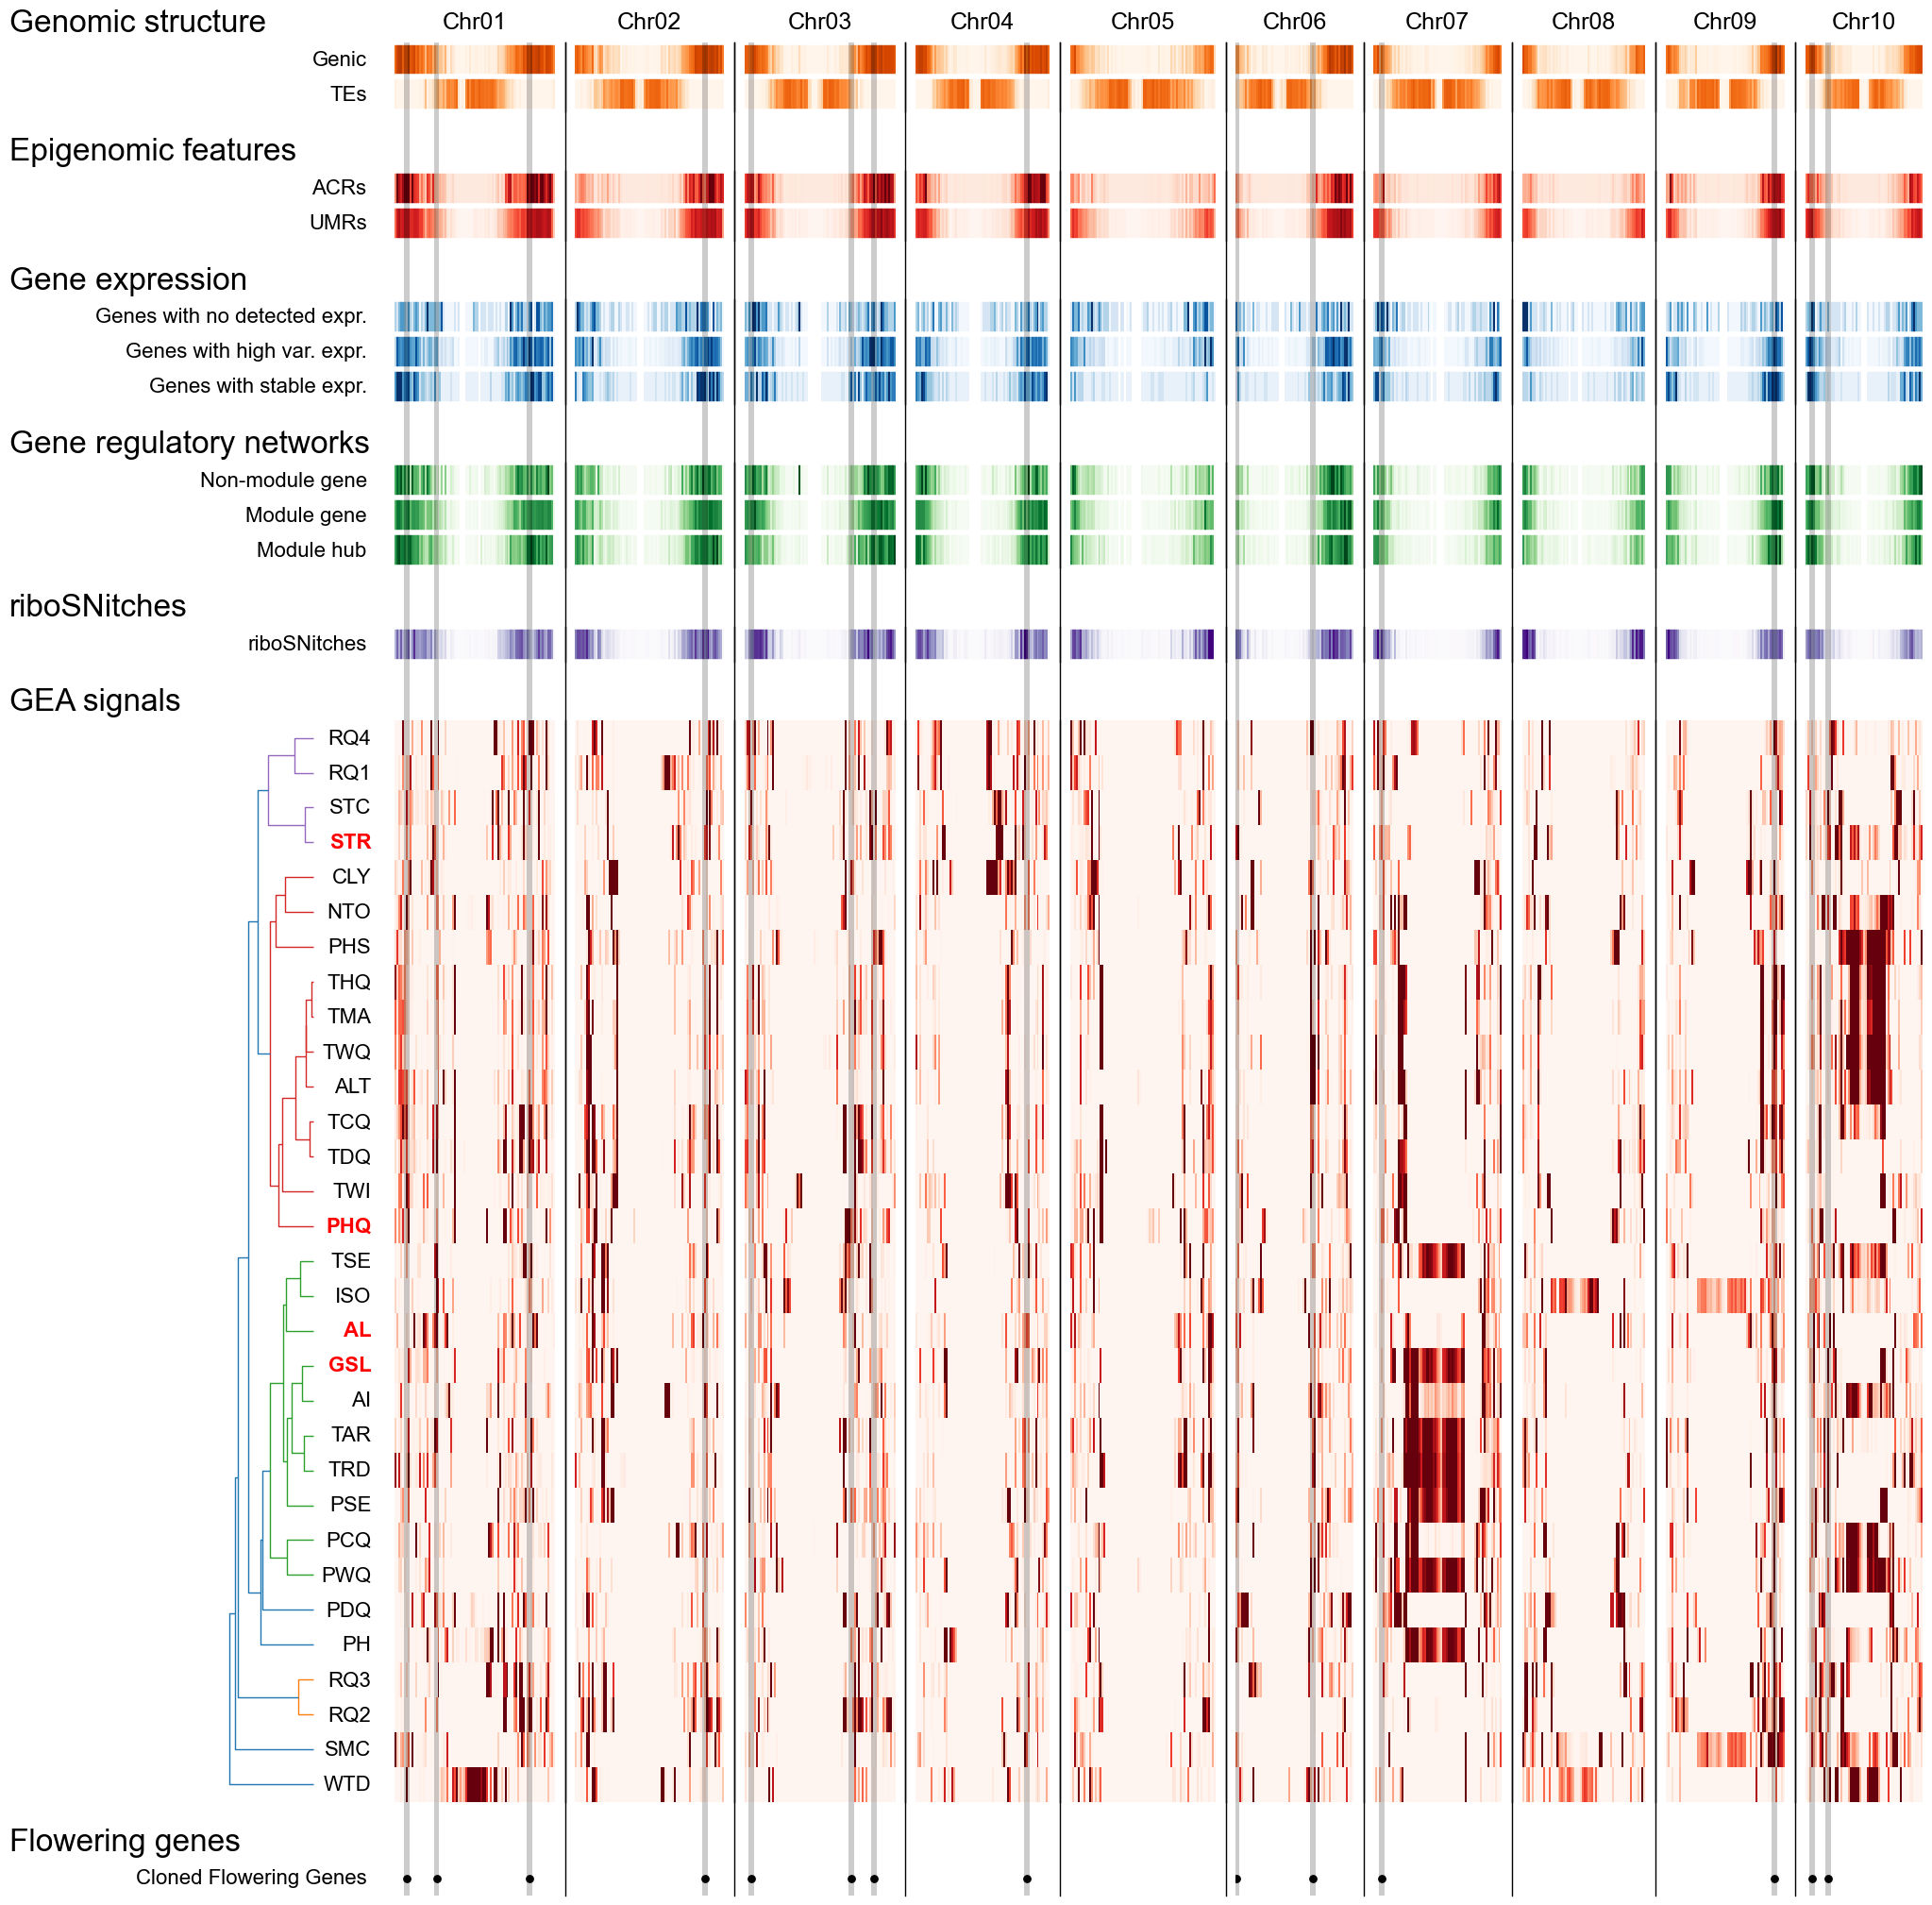

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.csv.gz'}


In [33]:
import matplotlib.pyplot as plt

figsize = (29.7 * 0.7, 21)
label_fontsize = 16
title_fontsize = 24
hspace = 0.275
wspace = 0.15

main_landscape_plot = plot_genomic_gea_landscape(
    feature_summary_csv, gea_enrichment_csv, cloned_bins_csv,
    environment_metadata_csv, correlation_csv, f'{landscape_prefix}.main',
    panel='main', window_size=window_size, figsize=figsize,
    label_fontsize=label_fontsize, title_fontsize=title_fontsize,
    hspace=hspace, wspace=wspace, highlight_env_ids=key_environment_ids,
)
plt.show()
print(main_landscape_plot['files'])


[04:35:24] Exported supp landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp


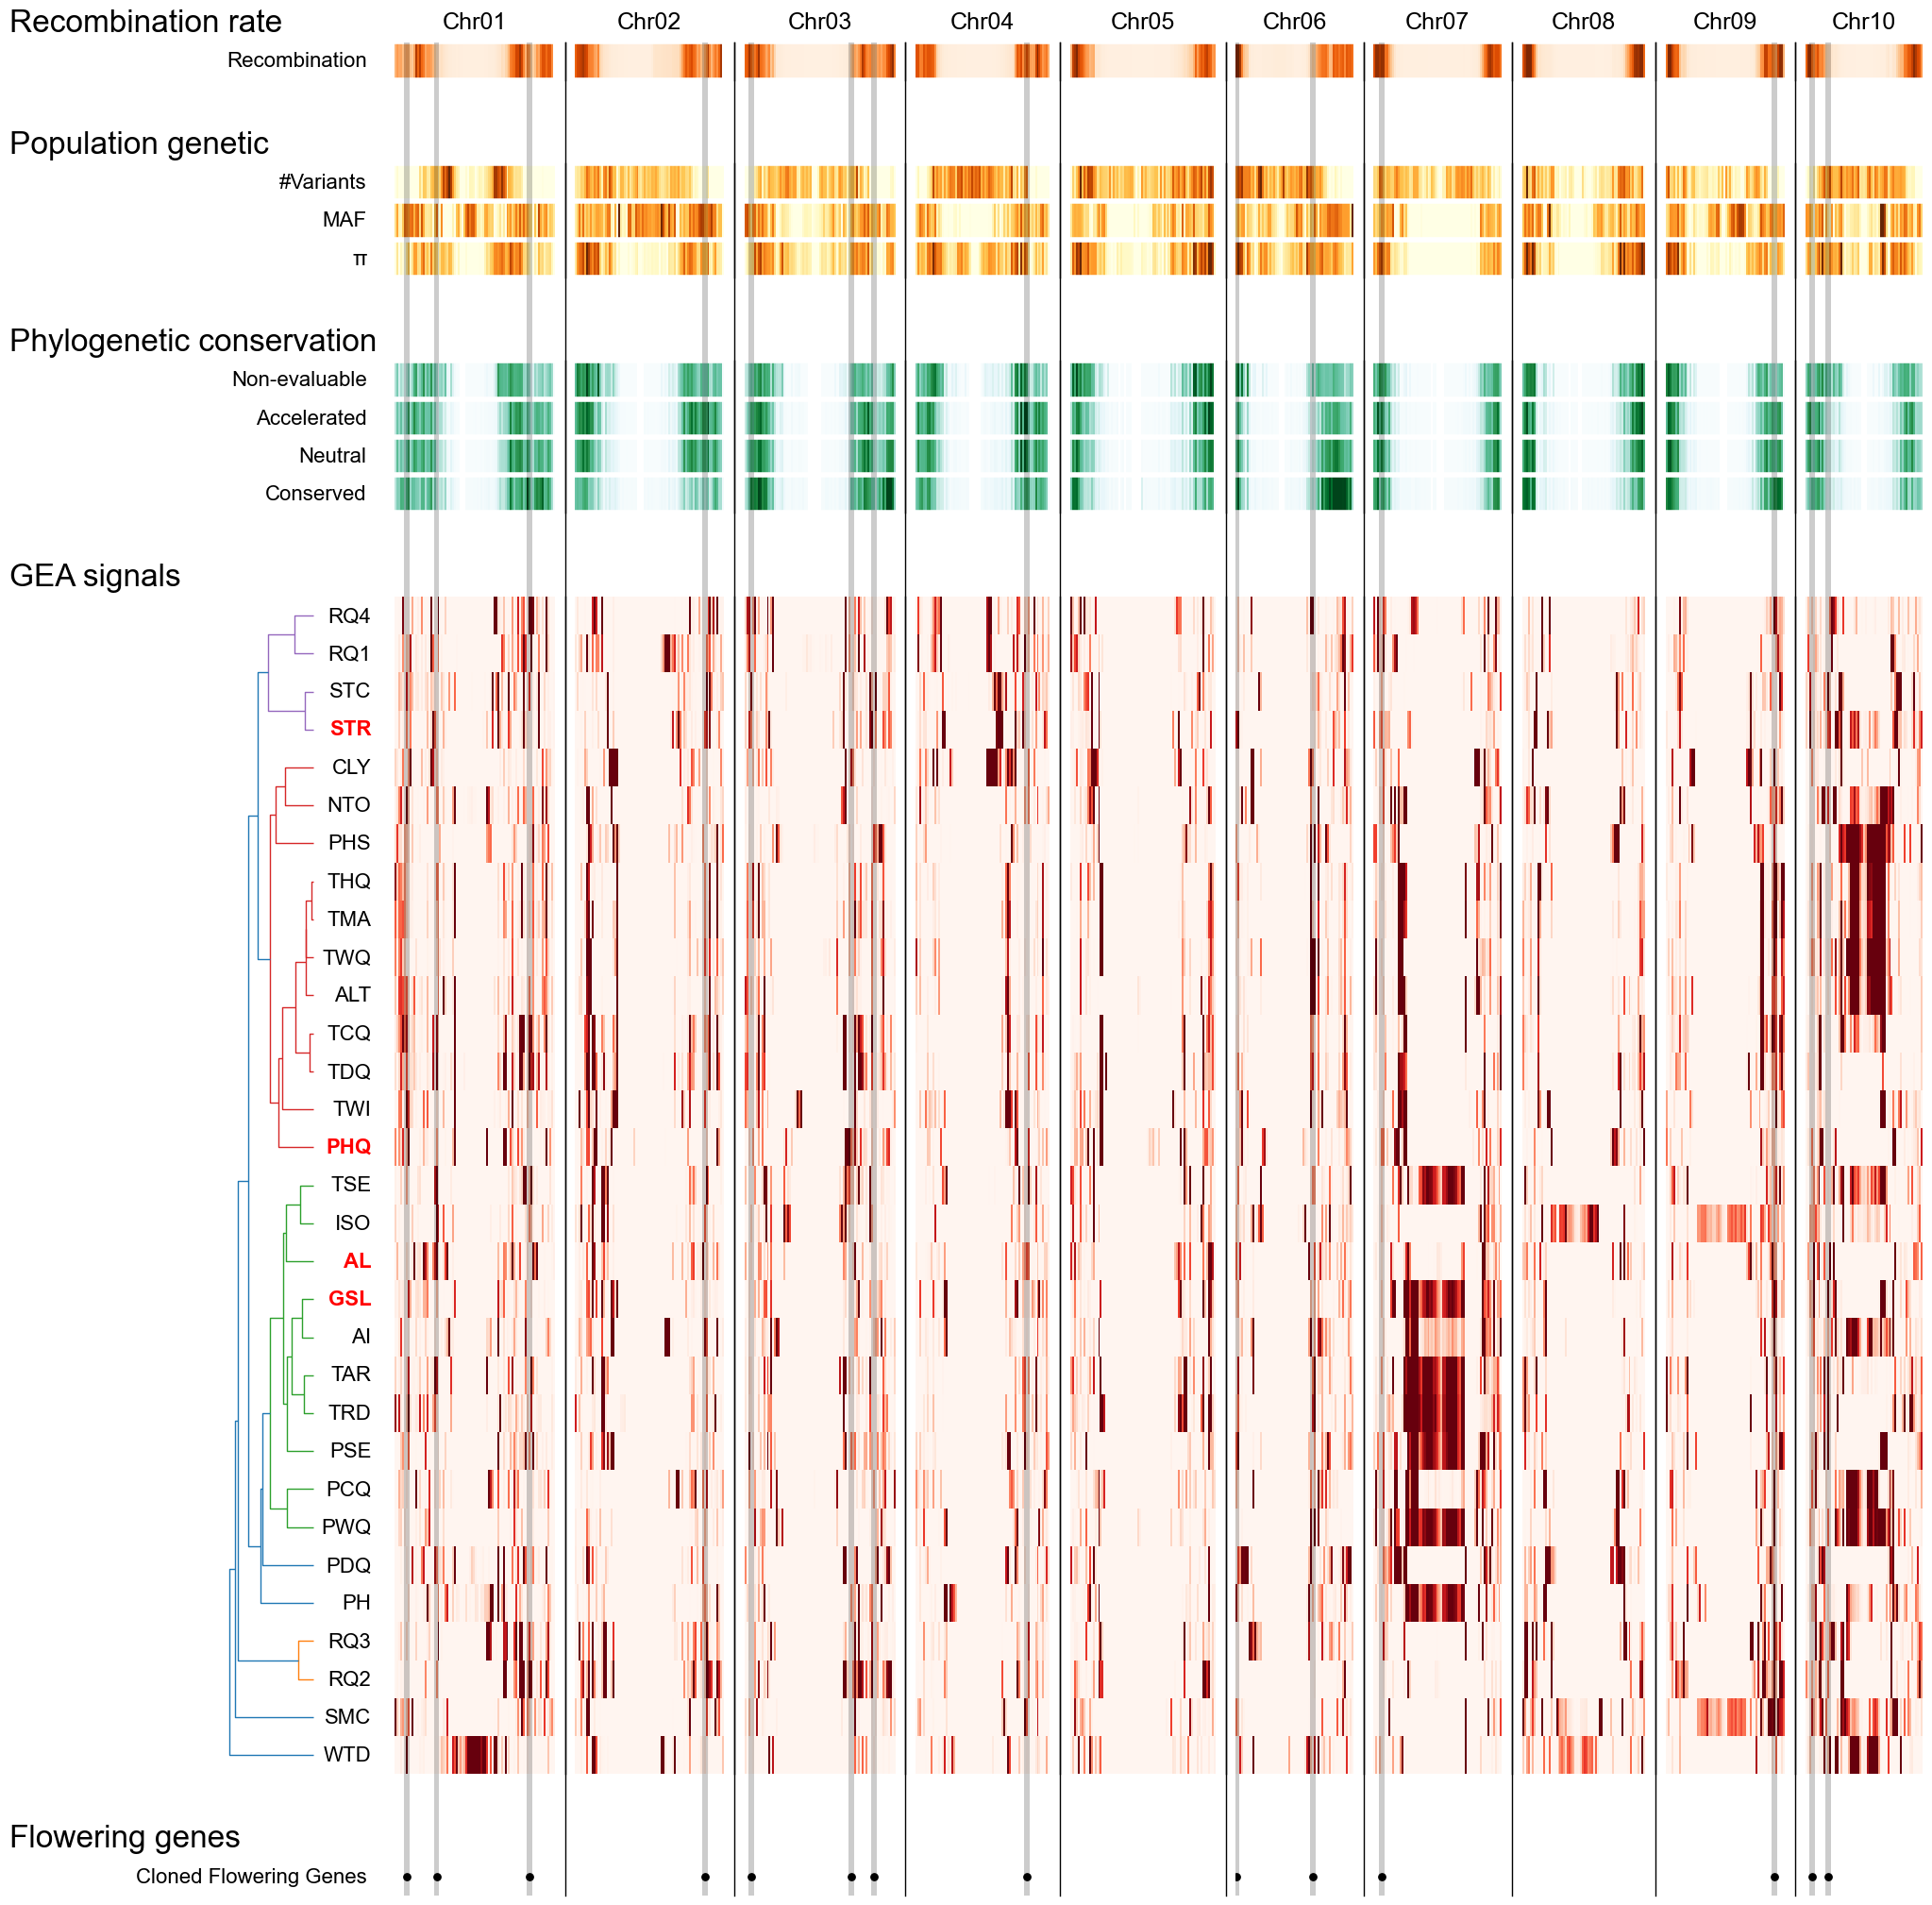

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.csv.gz'}


In [34]:
supp_landscape_plot = plot_genomic_gea_landscape(
    feature_summary_csv, gea_enrichment_csv, cloned_bins_csv,
    environment_metadata_csv, correlation_csv, f'{landscape_prefix}.supp',
    panel='supp', window_size=window_size, figsize=figsize,
    label_fontsize=label_fontsize, title_fontsize=title_fontsize,
    hspace=hspace, wspace=wspace, highlight_env_ids=key_environment_ids,
)
plt.show()
print(supp_landscape_plot['files'])


## 4. Flowering-time genes

Examine environmental associations of flowering-time genes, their relationships with cis-eQTL signals, and the contribution of coding and non-coding variation.


## 4. 开花时间基因

考察开花时间基因的环境关联、其与cis-eQTL信号的关系，以及编码和非编码变异的贡献。


### 4.1 Gene-level GEA enrichment

Test the overlap between flowering-time genes and the top 5% of MAGMA associations for four key environments. Compare the observed Jaccard index with 1,000 circular shifts of flowering-time labels within each chromosome.


### 4.1 基因级GEA富集

检验开花时间基因与四个重点环境变量中MAGMA关联最强的5%基因的重叠。将观测Jaccard指数与1,000次染色体内开花时间标签循环移位的结果比较。


In [35]:
import json
import gzip
import numpy as np
from src.enrich import gene_contrast_runner

contrast_id = 'flowering_time_genes'
key_environment_ids = ['bio18', 'gsl', 'al', 'striga']
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrast = json.load(handle)[contrast_id]
enrichment_environment_ids = key_environment_ids
permutations = 1000
top_percent = 0.05
enrichment_dir = f'{results_dir}/enrichment/flowering_time_genes'
os.makedirs(enrichment_dir, exist_ok=True)
enrichment_result_file = f'{enrichment_dir}/{contrast_id}.enrichment.json.gz'
figure_prefix = f'{enrichment_dir}/{contrast_id}'


In [36]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing flowering-time gene associations')
gene_associations_df = pd.read_hdf(f'{results_dir}/gene_contexts.h5', key='df')
if not gene_associations_df['ID'].is_unique:
    raise ValueError('Gene IDs must be unique for association alignment.')
for env_id in enrichment_environment_ids:
    gene_gwas_file = f'{results_dir}/gwas/{env_id}/{env_id}.magma/{env_id}.magma.gwas_df.h5'
    gene_gwas_df = pd.read_hdf(gene_gwas_file, key='df')[['ID', 'P_VALUE']]
    gene_gwas_df[env_id] = -np.log10(gene_gwas_df['P_VALUE'])
    gene_associations_df = gene_associations_df.merge(
        gene_gwas_df[['ID', env_id]], on='ID', how='left', validate='one_to_one',
    )
enrichment_result_file = gene_contrast_runner(
    contrast_id, contrast, gene_associations_df, enrichment_environment_ids,
    enrichment_dir, permutations=permutations, top_percent=top_percent,
)
print(f'[{datetime.now():%H:%M:%S}] Gene-level enrichment ready ({perf_counter() - stage_start:.1f}s)')
print(f'Results: {enrichment_result_file}')


[04:35:26] Preparing flowering-time gene associations
Enrichment results already exist for contrast flowering_time_genes, skipping.
[04:35:26] Gene-level enrichment ready (0.3s)
Results: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.enrichment.json.gz


#### Display flowering-time gene enrichment

Light-blue histograms show permutation distributions; red dashed lines mark observed Jaccard indices. Each panel reports a two-sided empirical P value.


#### 展示开花时间基因富集

浅蓝色直方图展示置换分布，红色虚线标记观测Jaccard指数。每个面板标注双侧经验P值。


Figure and data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.{pdf,png,csv.gz,histogram.csv.gz}


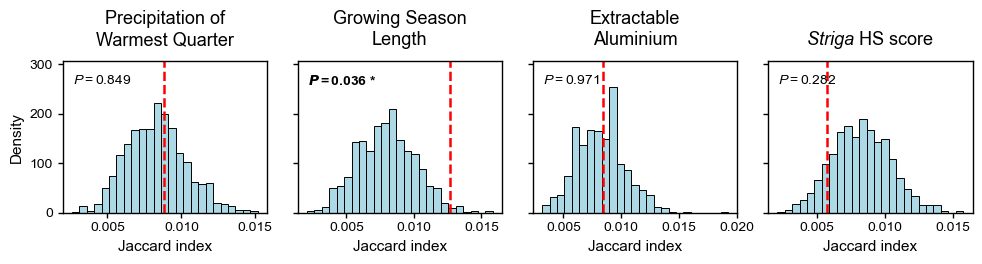

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.csv.gz', 'histogram_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.histogram.csv.gz'}


In [37]:
import matplotlib.pyplot as plt
from src.enrich import plot_gene_enrichment_histogram

environment_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv')
histogram_bins = 25
enrichment_plot = plot_gene_enrichment_histogram(
    enrichment_result_file, enrichment_environment_ids, environment_metadata_df,
    output_prefix=figure_prefix, figsize=(10, 2.8), bins=histogram_bins,
)
fig, axes = enrichment_plot['figure'], enrichment_plot['axes']
plot_df = enrichment_plot['plot_data']
plt.show()
print(enrichment_plot['files'])


### 4.2 GEA and expression associations at individual flowering-time genes

Expression GWAS (expGWAS) was previously performed in 318 samples with expression data. SNPs and indels were filtered at MAF ≥0.05, heterozygosity ≤0.05 and missingness ≤0.5. Genes with TPM >1 in more than 20% of samples were retained; expression was transformed using log2(TPM + 1) followed by an inverse normal transformation. GEMMA models included a kinship matrix, and cis-eQTLs were tested within gene bodies and 15 kb flanks on each side, with 100 phenotype permutations per gene.


### 4.2 个别开花时间基因的GEA与表达关联

前期在318个具有表达数据的样本中开展了表达GWAS（expGWAS）。SNP和indel按MAF ≥0.05、杂合率 ≤0.05和缺失率 ≤0.5过滤。保留超过20%样本中TPM >1的基因，对表达量进行log2(TPM + 1)及逆正态转换。GEMMA模型纳入亲缘矩阵，在基因本体及两侧各15 kb范围内检验cis-eQTL，并为每个基因进行100次表型置换。


#### Estimate empirical cis-eQTL FDR

Each observed or permuted value is the minimum nominal P value across a gene's cis region. At each observed P value, empirical FDR is the cumulative fraction of permutation minima divided by the cumulative fraction of observed minima. Linear interpolation identifies the nominal P threshold at FDR = 0.05.


#### 估计cis-eQTL的经验FDR

每个真实或置换值均为一个基因cis区域内最小的nominal P值。在每个真实P值处，以置换最小P值的累积比例除以真实最小P值的累积比例，计算经验FDR。通过线性插值得到FDR = 0.05对应的nominal P阈值。


In [38]:
from src.eqtl import (
    prepare_cis_eqtl_fdr, plot_cis_eqtl_fdr, prepare_cis_eqtl_egenes,
    prepare_flowering_gene_loci, plot_flowering_gene_locus,
)

cis_eqtl_dir = f'{results_dir}/cis_eQTL'
permutation_pval_csv = f'{source_dir}/eQTL_perm_pval.csv.gz'
cis_eqtl_site_csv = f'{source_dir}/cis_eQTL_all_genes_sites.csv.gz'
tpm_csv = f'{source_dir}/RNAseqPanel.tpm.csv.gz'
fdr_curve_csv = f'{cis_eqtl_dir}/cis_eQTL.fdr.csv.gz'
cis_eqtl_threshold_csv = f'{cis_eqtl_dir}/cis_eQTL.threshold.csv.gz'
fdr_threshold = 0.05
force_recompute = False


In [39]:
fdr_result = prepare_cis_eqtl_fdr(
    permutation_pval_csv, cis_eqtl_dir, fdr_threshold=fdr_threshold,
    force_recompute=force_recompute,
)
reference_pvalue = 0.0008624278152523955
print(f"Observed minima: {int(fdr_result['summary'].iloc[0]['N_OBS']):,}; reference: 18,854")
print(f"Permuted minima: {int(fdr_result['summary'].iloc[0]['N_PERM']):,}; reference: 1,885,400")
print(f"P threshold: {fdr_result['pvalue_threshold']:.16g}; reference: {reference_pvalue:.16g}")
print(f"Threshold difference: {fdr_result['pvalue_threshold'] - reference_pvalue:.3g}")
fdr_result['summary']


[04:35:28] Reusing empirical FDR: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.fdr.csv.gz
Observed minima: 18,854; reference: 18,854
Permuted minima: 1,885,400; reference: 1,885,400
P threshold: 0.0008624278152523001; reference: 0.0008624278152523955
Threshold difference: -9.54e-17


,FDR_THRESHOLD,P_VALUE_THRESHOLD,N_OBS,N_PERM,PERMUTATIONS_PER_GENE
0,0.05,0.000862,18854,1885400,100.0


##### Display the empirical FDR curve

The red line marks FDR = 0.05; the green line marks its corresponding nominal P threshold. This is a gene-level empirical FDR curve derived from cis-region minima.


##### 展示经验FDR曲线

红线标记FDR = 0.05，绿线标记对应的nominal P阈值。这是依据cis区域最小P值构建的基因水平经验FDR曲线。


[04:35:28] Plotting empirical cis-eQTL FDR


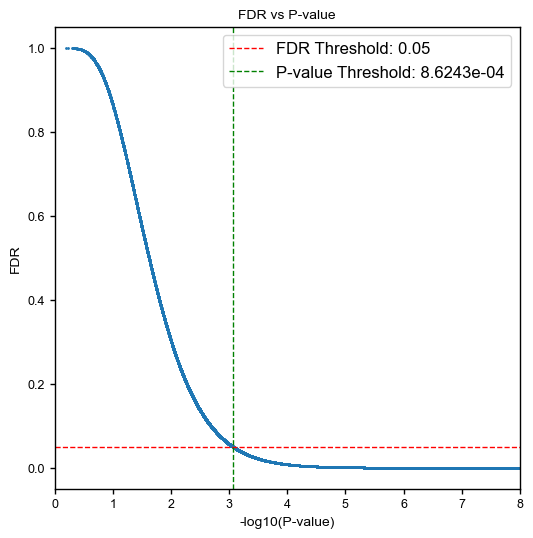

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.csv.gz'}


In [40]:
import matplotlib.pyplot as plt

fdr_plot = plot_cis_eqtl_fdr(
    fdr_curve_csv, cis_eqtl_threshold_csv, f'{cis_eqtl_dir}/cis_eQTL.empirical_fdr',
    figsize=(6, 6),
)
plt.show()
print(fdr_plot['files'])


#### Identify eGenes

An eGene has at least one tested cis variant with nominal P strictly below the empirical threshold. Count all eligible genes, irrespective of flowering-time annotation, and retain their IDs for subsequent analyses.


#### 识别eGenes

eGene定义为至少一个受检cis位点的nominal P严格小于经验阈值的基因。统计所有符合条件的基因，不限于开花时间基因，并保留其ID用于后续分析。


In [41]:
egene_result = prepare_cis_eqtl_egenes(
    cis_eqtl_site_csv, cis_eqtl_threshold_csv, cis_eqtl_dir,
    force_recompute=force_recompute,
)
egene_ids = egene_result['gene_ids']
egene_list = egene_result['files']['gene_list']
print(f'eGenes: {len(egene_ids):,};')
print(f'eGene list: {egene_list}')
egene_result['summary'].head()


[04:35:30] Reusing 12,454 eGenes
eGenes: 12,454;
eGene list: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL_gene_id_list.txt


,GENE,N_TESTED,N_SIGNIFICANT,LEAD_ID,CHROM,LEAD_POS,MIN_P,P_VALUE_THRESHOLD
0,Sobic.001G000300.v5.1,188,15,SNP_Chr01_39503,Chr01,39503,4.323326e-08,0.000862
1,Sobic.001G000400.v5.1,314,24,SNP_Chr01_50639,Chr01,50639,2.760949e-04,0.000862
2,Sobic.001G000700.v5.1,173,91,SNP_Chr01_66594,Chr01,66594,5.089408e-32,0.000862
3,Sobic.001G000800.v5.1,191,27,SNP_Chr01_92806,Chr01,92806,3.358361e-04,0.000862
4,Sobic.001G001300.v5.1,214,88,INDEL_Chr01_135901,Chr01,135901,2.731979e-15,0.000862


#### Prepare individual flowering-time loci

For each gene, select the strongest environmental association among shared variants passing the empirical cis-eQTL P threshold. Regional panels show GEA and expression associations; the same marker defines the two homozygous genotype groups (0 and 2) in the environment and raw-TPM boxplots.

The regional view extends 18 kb beyond the gene, while eQTL tests cover only the original 15 kb flanks. The eQTL horizontal line uses the global empirical threshold; the expression boxplot title reports BH FDR calculated across all tested cis variants of that gene. These are distinct corrections.


#### 准备个别开花时间基因的区域数据

对每个基因，在通过经验cis-eQTL P阈值的共享位点中，选择环境关联最强的位点。区域图展示GEA和表达关联；环境值与原始TPM箱线图均按同一标记分为两个纯合基因型组（0和2）。

区域展示范围延伸至基因两侧各18 kb，但eQTL检验仅覆盖原有15 kb flank。eQTL水平线使用全局经验阈值；表达箱线图标题中的BH FDR则基于该基因全部受检cis位点计算，两者是不同的校正。


In [42]:
locus_output_dir = f'{results_dir}/flowering_time_genes'
all_samples_vcf_file = f'{results_dir}/Sorghum_d8.allChr.imputed_snpeff.vcf.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
gwas_dir = f'{results_dir}/gwas'
gene_plot_configs = [
    dict(gene_id='Sobic.009G257300.v5.1', gene_name='ELF3', env_id='gsl',
         marker_index=0, marker_id=None, flank_size=18000),
    dict(gene_id='Sobic.004G161701.v5.1', gene_name='LWD1', env_id='gsl',
         marker_index=0, marker_id=None, flank_size=18000),
]


In [43]:
locus_summary = prepare_flowering_gene_loci(
    gene_plot_configs, cis_eqtl_site_csv, tpm_csv, cis_eqtl_threshold_csv,
    all_samples_vcf_file, gff_file, landrace_metadata_csv,
    environment_metadata_csv, gwas_dir, locus_output_dir,
    force_recompute=force_recompute,
)
locus_summary


[04:35:31] Reusing prepared flowering-gene loci


,GENE,GENE_NAME,ENV_ID,ENV_NAME,ENV_UNITS,CHROM,START,END,FLANK_SIZE,MARKER_ID,...,TOP1_P,TOP5_P,EQTL_THRESHOLD,N_CIS_TESTED,N_ENV_REF,N_ENV_ALT,N_EXPR_REF,N_EXPR_ALT,LOCUS_FILE,SUMMARY_FILE
0,Sobic.009G257300.v5.1,ELF3,gsl,Grow.Season.Len,days,Chr09,62951808,62992860,18000,SNP_Chr09_62969740,...,0.008475,0.049922,0.000862,158,198,237,218,96,/lustre/home/dobby/Work/Project/functional-gen...,/lustre/home/dobby/Work/Project/functional-gen...
1,Sobic.004G161701.v5.1,LWD1,gsl,Grow.Season.Len,days,Chr04,53482206,53521352,18000,SNP_Chr04_53506205,...,0.008475,0.049922,0.000862,111,183,250,186,120,/lustre/home/dobby/Work/Project/functional-gen...,/lustre/home/dobby/Work/Project/functional-gen...


#### Display individual flowering-time loci

Blue and pink points show GEA and eQTL associations; green points highlight the shared marker. Black gene models mark the target gene and gray models show neighboring genes. Boxplot titles report the marker's GEA P value and gene-specific BH FDR, rather than tests between the displayed groups.


#### 展示个别开花时间基因的区域关联

蓝色和粉色散点分别表示GEA和eQTL关联，绿色散点标记共享位点。黑色基因结构表示目标基因，灰色表示邻近基因。箱线图标题报告标记位点的GEA P值和基因内BH FDR，并非展示组之间重新检验的结果。


[04:35:31] Plotting flowering-gene locus: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.locus.csv.gz


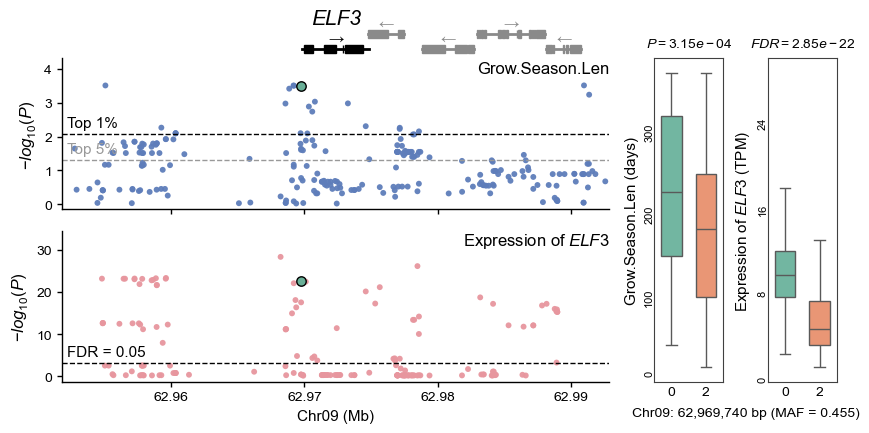

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.csv.gz'}


In [44]:
plot_params = dict(
    figsize=(10, 4.2), title_fontsize=15, panel_label_fontsize=11,
    y_label_fontsize=12, tick_fontsize=10, step_mb=0.01,
)
elf3_config = gene_plot_configs[0]
elf3_prefix = f"{locus_output_dir}/{elf3_config['gene_id']}.{elf3_config['env_id']}"
elf3_locus_plot = plot_flowering_gene_locus(
    f'{elf3_prefix}.locus.csv.gz', f'{elf3_prefix}.summary.csv.gz',
    f'{elf3_prefix}.compact', **plot_params,
)
plt.show()
print(elf3_locus_plot['files'])


[04:35:33] Plotting flowering-gene locus: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.locus.csv.gz


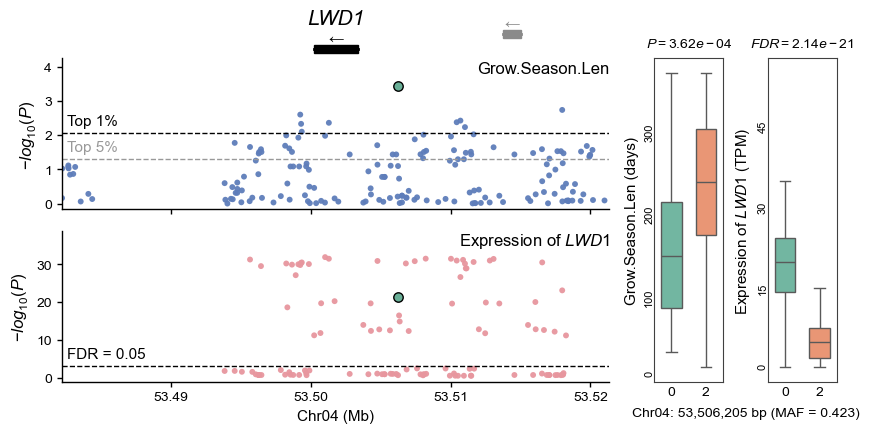

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.csv.gz'}


In [45]:
lwd1_config = gene_plot_configs[1]
lwd1_prefix = f"{locus_output_dir}/{lwd1_config['gene_id']}.{lwd1_config['env_id']}"
lwd1_locus_plot = plot_flowering_gene_locus(
    f'{lwd1_prefix}.locus.csv.gz', f'{lwd1_prefix}.summary.csv.gz',
    f'{lwd1_prefix}.compact', **plot_params,
)
plt.show()
print(lwd1_locus_plot['files'])


### 4.3 Flowering-gene enrichment among regulatory GEA candidates

Test whether flowering-time genes are enriched among GSL-associated genes whose lead environmental and cis-eQTL variants are linked. Compare Literature-curated flowering genes and the complete flowering-gene set separately. The curated set has literature-supported functional annotations and is more credible than orthology-based predictions. Both comparisons use all eGenes as the background, intersecting each flowering-gene set with this background.


### 4.3 调控相关GEA候选基因中的开花基因富集

检验开花时间基因是否富集于lead环境关联位点与lead cis-eQTL位点存在连锁的GSL关联基因。分别检验Literature-curated开花基因和完整开花基因集合。文献整理集合的功能注释具有文献支持，相较于基于同源关系的预测更可信。两组均以全部eGenes为背景，各开花基因集合分别与该背景取交集。


#### Compare lead cis-eQTL and GEA variants

Within each eGene body and its 15 kb flanks, independently select the strongest cis-eQTL passing the empirical P threshold and the strongest GSL association within the genome-wide top 5% of nominal P values. Calculate squared Pearson correlation (r²) between their allele dosages in the union of landrace and RNA-panel samples, counting each sample once. Regulatory GEA candidates have r² ≥0.25. Missing genotypes are excluded pairwise; invariant variants have undefined correlation.


#### 比较lead cis-eQTL与GEA位点

在每个eGene本体及两侧各15 kb范围内，独立选择通过经验P阈值的最强cis-eQTL，以及全基因组nominal P值排名前5%中的最强GSL关联位点。在地方品种与RNA panel样本的并集中，计算两个位点等位基因剂量的Pearson相关系数平方（r²），每个样本只计一次。以r² ≥0.25定义调控相关GEA候选基因。缺失基因型按位点对排除；无变异的位点不计算相关性。


In [46]:
from src.eqtl import (
    prepare_regulatory_gea_genes, plot_regulatory_gea_r2,
    prepare_regulatory_gea_enrichment,
)

env_id = 'gsl'
flank_size = 15000
top_fraction = 0.05
r2_threshold = 0.25
force_recompute = False
cis_eqtl_dir = f'{results_dir}/cis_eQTL'
output_prefix = f'{cis_eqtl_dir}/reg_GEA.{env_id}.flank{flank_size}'
egene_list = f'{cis_eqtl_dir}/cis_eQTL_gene_id_list.txt'
cis_eqtl_threshold_csv = f'{cis_eqtl_dir}/cis_eQTL.threshold.csv.gz'
cis_eqtl_site_csv = f'{source_dir}/cis_eQTL_all_genes_sites.csv.gz'
tpm_csv = f'{source_dir}/RNAseqPanel.tpm.csv.gz'
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
all_samples_vcf_file = f'{results_dir}/Sorghum_d8.allChr.imputed_snpeff.vcf.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
gwas_h5 = f'{results_dir}/gwas/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
pairs_csv = f'{output_prefix}.pairs.csv.gz'
comparison_summary_csv = f'{output_prefix}.summary.csv.gz'


In [47]:
lead_comparison = prepare_regulatory_gea_genes(
    egene_list, cis_eqtl_site_csv, cis_eqtl_threshold_csv, gwas_h5,
    tpm_csv, landrace_metadata_csv, all_samples_vcf_file, gff_file, output_prefix,
    env_id=env_id, flank_size=flank_size,
    top_fraction=top_fraction, r2_threshold=r2_threshold,
    force_recompute=force_recompute,
)
print(lead_comparison['pairs']['STATUS'].value_counts())
print(f"Candidate gene list: {lead_comparison['files']['gene_list']}")
lead_comparison['summary']


[04:35:35] Reusing regulatory GEA candidates: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000
STATUS
compared              10596
no_top_gea_variant     1858
Name: count, dtype: int64
Candidate gene list: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.gene_ids.txt


,ENV_ID,N_EGENES,N_LEAD_PAIRS,N_VALID_CORRELATIONS,N_REG_GEA,N_RNA_SAMPLES,N_LANDRACE_SAMPLES,N_UNION_SAMPLES,FLANK_SIZE,TOP_FRACTION,GEA_P_THRESHOLD,EQTL_P_THRESHOLD,R2_THRESHOLD
0,gsl,12454,10596,10596,2001,318,443,757,15000,0.05,0.049922,0.000862,0.25


#### Display lead-variant linkage

The histogram shows r² for genes with both eligible lead variants and defined correlation. The dashed line marks the candidate threshold. High r² provides evidence of linked association signals; it does not establish a shared causal variant.


#### 展示lead位点间的连锁关系

直方图展示同时具有两个符合条件的lead位点、且相关性可计算的基因的r²分布。虚线标记候选筛选阈值。较高的r²支持关联信号存在连锁联系，但不能据此确定共享因果位点。


[04:35:35] Plotting lead-variant genotype correlations


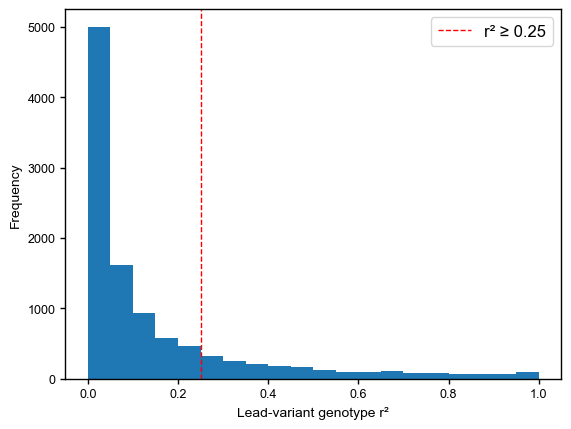

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.csv.gz', 'histogram': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.histogram.csv.gz'}


In [48]:
import matplotlib.pyplot as plt

histogram_bins = 20
r2_plot = plot_regulatory_gea_r2(
    pairs_csv, comparison_summary_csv, f'{output_prefix}.r2',
    bins=histogram_bins, figsize=(6.4, 4.8),
)
plt.show()
print(r2_plot['files'])


#### Test curated flowering-gene enrichment

Use one-sided hypergeometric and Fisher exact tests to compare the overlap with the expectation under the full eGene background. Report the observed and expected overlaps, enrichment ratio and overlapping genes. eGenes without a local top-5% GEA variant remain in the background.


#### 检验文献支持的开花基因富集

以完整eGene集合为背景，使用单侧超几何检验与Fisher精确检验，比较观测重叠与背景期望。报告观测和期望重叠数、富集倍数及重叠基因。没有局部Top 5% GEA位点的eGenes仍保留在背景中。


In [49]:
flowering_csv = f'{source_dir}/Sorghum_flowering_genes.csv'
annotation_source = 'Literature-curated genes'
enrichment_prefix = f'{output_prefix}.flowering_time_genes.curated'
curated_enrichment = prepare_regulatory_gea_enrichment(
    f'{output_prefix}.background.csv.gz', f'{output_prefix}.candidates.csv.gz',
    flowering_csv, enrichment_prefix,
    annotation_source=annotation_source,
    force_recompute=force_recompute,
)
curated_enrichment['summary']


[04:35:36] Reusing flowering-gene regulatory GEA enrichment


,BACKGROUND,ANNOTATION_SOURCE,N_BACKGROUND,N_FLOWERING,N_REG_GEA,N_OVERLAP,EXPECTED_OVERLAP,FOLD_ENRICHMENT,ODDS_RATIO,HYPERGEOM_P,FISHER_GREATER_P
0,eGenes,Literature-curated genes,12454,25,2001,11,4.016782,2.738511,4.121644,0.000889,0.000889


In [50]:
curated_enrichment['contingency']


,FLOWERING_CLASS,REG_GEA,NOT_REG_GEA
0,Literature-curated genes,11,14
1,Other eGenes,1990,10439


#### Test enrichment of all flowering genes

Repeat the same tests with the complete flowering-gene set, including orthology-based annotations, using the same eGene background and regulatory GEA candidates.


#### 检验全部开花基因的富集

对包含同源预测注释的完整开花基因集合进行相同检验，沿用相同的eGene背景和调控相关GEA候选集合。


In [51]:
enrichment_prefix = f'{output_prefix}.flowering_time_genes.all'
flowering_enrichment = prepare_regulatory_gea_enrichment(
    f'{output_prefix}.background.csv.gz', f'{output_prefix}.candidates.csv.gz',
    flowering_csv, enrichment_prefix,
    force_recompute=force_recompute,
)
flowering_enrichment['summary']


[04:35:37] Reusing flowering-gene regulatory GEA enrichment


,BACKGROUND,ANNOTATION_SOURCE,N_BACKGROUND,N_FLOWERING,N_REG_GEA,N_OVERLAP,EXPECTED_OVERLAP,FOLD_ENRICHMENT,ODDS_RATIO,HYPERGEOM_P,FISHER_GREATER_P
0,eGenes,All flowering genes,12454,139,2001,24,22.333307,1.074628,1.091298,0.384134,0.384134


In [52]:
flowering_enrichment['contingency']


,FLOWERING_CLASS,REG_GEA,NOT_REG_GEA
0,All flowering genes,24,115
1,Other eGenes,1977,10338


### 4.4 Non-coding versus coding GEA signals in flowering-time genes

Test whether non-coding variants have stronger environmental associations than coding variants within flowering-gene bodies and their 2 kb flanks. Compare Literature-curated genes first, because their functional annotations have stronger support, then the complete flowering-gene set. Non-coding sites exclude CDS and include introns, UTRs and flanking regions. Both groups use the same genome-wide variant set with MAF ≥0.05.


### 4.4 开花时间基因中非编码与编码区的GEA信号比较

检验开花基因本体及两侧2 kb内，非编码位点的环境关联是否强于编码位点。先分析功能注释依据更充分的Literature-curated基因，再分析完整开花基因集合。非编码位点排除CDS，包括内含子、UTR及侧翼区域。两组均使用同一套MAF ≥0.05的全基因组变异。


#### Compare association strength

For each environmental variable, divide the 95th percentile of non-coding −log10(P) by that of coding sites. A ratio above 1 indicates stronger non-coding signals in the upper tail. Use 1,000 chromosome-wise circular shifts of site labels for a two-sided empirical test. Evaluate all sites together and the five configured MAF strata, for the same four key environmental variables as above.


#### 比较关联强度

对每个环境变量，以非编码位点−log10(P)的95百分位数除以编码位点的对应值。比值大于1表示非编码位点的上尾关联信号更强。通过1,000次染色体内位点标签循环置换进行双侧经验检验。分别分析全部位点及配置中的五个MAF分层，沿用前述四个重点环境变量。


In [53]:
import json
import gzip
import pickle
import numpy as np
from tqdm.auto import tqdm
from src.enrich import site_contrast_runner, filter_df_by_set_expr, plot_enrichment_and_overlap
from src.ld import calculate_ld_matrix, calculate_contrast_ld_overlap

contrasts_json = f'{project_dir}/config/contrasts_settings.json'
with open(contrasts_json) as handle:
    contrasts_settings = json.load(handle)
contrast_ids = ['core_flowering_non_coding_vs_coding', 'flowering_non_coding_vs_coding']
site_contexts_h5 = f'{results_dir}/site_contexts.genome.maf0.05.h5'
gwas_dir = f'{results_dir}/gwas'
landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
enrichment_environment_ids = list(key_environment_ids)
permutations = 1000
top_percent = 0.05
pool_num = project_config['resources']['interactive']['cores']
ld_window_size = 15000
min_r2 = 0.5
bin_width = 0.05
random_seed = 42
enrichment_dir = f'{results_dir}/enrichment/flowering_time_genes/non_coding_vs_coding'
os.makedirs(enrichment_dir, exist_ok=True)
ld_pairs_h5 = f'{enrichment_dir}/flowering_sites.ld{ld_window_size}.r2{min_r2}.h5'
ld_overlap_dir = f'{enrichment_dir}/ld_overlap.{".".join(enrichment_environment_ids)}'
os.makedirs(ld_overlap_dir, exist_ok=True)


In [54]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing flowering-site association scores')

stratify_columns = [s for s in contrasts_settings[contrast_ids[0]]['maf_stratify'] if s != 'all']
context_columns = ['ID', 'CHROM', 'POS', 'genic_2kb', 'CDS',
                   'core_flowering_time_genes', 'flowering_time_genes'] + stratify_columns
context_df = pd.read_hdf(site_contexts_h5, key='df')[context_columns].copy()
selected = np.zeros(len(context_df), dtype=bool)
for contrast_id in contrast_ids:
    contrast = contrasts_settings[contrast_id]
    selected |= (filter_df_by_set_expr(context_df, contrast['foreground'])
                 | filter_df_by_set_expr(context_df, contrast['background']))
context_df = context_df.loc[selected].copy()
for env_id in tqdm(enrichment_environment_ids, desc='Environmental association scores'):
    gwas_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
    associations_df = pd.read_hdf(gwas_h5, key='df')[['ID', 'P_WALD']]
    associations_df[env_id] = -np.log10(associations_df['P_WALD'])
    context_df = context_df.merge(associations_df[['ID', env_id]], on='ID',
                                  how='left', validate='one_to_one')
context_df = context_df.set_index('ID', drop=False)
print(f'[{datetime.now():%H:%M:%S}] Prepared {len(context_df):,} sites in {perf_counter() - stage_start:.1f}s')
context_df.head()


[04:35:38] Preparing flowering-site association scores


Environmental association scores: 100%|██████████| 4/4 [01:05<00:00, 16.40s/it]

[04:36:48] Prepared 25,643 sites in 69.9s


,ID,CHROM,POS,genic_2kb,CDS,core_flowering_time_genes,flowering_time_genes,maf_0.05_0.1,maf_0.1_0.2,maf_0.2_0.3,maf_0.3_0.4,maf_0.4_0.5,bio18,gsl,al,striga
ID,,,,,,,,,,,,,,,,
SNP_Chr01_471992,SNP_Chr01_471992,Chr01,471992,True,False,False,True,False,True,False,False,False,1.193164,2.538584,1.079465,0.128416
SNP_Chr01_472103,SNP_Chr01_472103,Chr01,472103,True,False,False,True,False,False,False,True,False,0.923091,0.102289,0.166733,0.166525
SNP_Chr01_472674,SNP_Chr01_472674,Chr01,472674,True,False,False,True,False,False,False,True,False,0.627005,0.473151,0.537114,0.190139
SNP_Chr01_472694,SNP_Chr01_472694,Chr01,472694,True,False,False,True,False,True,False,False,False,0.739367,0.400189,0.123560,0.061884
INDEL_Chr01_472923,INDEL_Chr01_472923,Chr01,472923,True,False,False,True,True,False,False,False,False,1.279725,0.792990,0.074617,0.566797


#### Evaluate cross-group linkage

Within 15 kb, quantify LD between non-coding and CDS variants using r² >0.5. Rank sites separately within each group and compare matching 5%-wide GEA-rank bins. The linkage score is the harmonic mean of the two groups' mean maximum scaled r² values; shuffled GEA scores provide a reference. Interpret non-coding association strength together with its linkage to coding signals.


#### 评估两组位点间的连锁联系

在15 kb内，以r² >0.5评估非编码与CDS位点间的LD。两组位点分别按GEA强度排序，比较对应的5%宽度排名区间。连锁指标为两组位点平均最大缩放r²的调和平均值，并以随机打乱GEA分数作为参照，用于结合编码信号的连锁联系理解非编码关联强度。


In [55]:
print(f'[{datetime.now():%H:%M:%S}] Preparing LD pairs')
if os.path.exists(ld_pairs_h5):
    ld_df = pd.read_hdf(ld_pairs_h5, key='df')
else:
    ld_df = calculate_ld_matrix(
        context_df, landraces_qc_vcf_file, ld_window_size=ld_window_size,
        min_r2=min_r2, pool_num=pool_num,
    )
    temporary_h5 = f'{ld_pairs_h5}.tmp'
    ld_df.to_hdf(temporary_h5, key='df', mode='w')
    os.replace(temporary_h5, ld_pairs_h5)
print(f'[{datetime.now():%H:%M:%S}] Retained {len(ld_df):,} LD pairs')
ld_df.head()


[04:36:48] Preparing LD pairs
LD pairs: 25643/25643 (100.0%) | elapsed 2.3s
[04:36:51] Retained 617,086 LD pairs


,INDEX_1,INDEX_2,R2
0,SNP_Chr01_8345872,SNP_Chr01_8346947,0.960754
1,SNP_Chr01_8345872,SNP_Chr01_8354116,0.808145
2,SNP_Chr01_8345872,SNP_Chr01_8354193,0.952187
3,SNP_Chr01_8346074,INDEL_Chr01_8354558,0.580129
4,SNP_Chr01_8346947,SNP_Chr01_8354116,0.828069


#### Literature-curated flowering genes


#### 文献支持的开花基因


In [56]:
contrast_id = 'core_flowering_non_coding_vs_coding'
contrast = contrasts_settings[contrast_id]
results_json_file = site_contrast_runner(
    contrast_id, contrast, context_df, enrichment_environment_ids, enrichment_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, enrichment_environment_ids, ld_df, ld_overlap_dir,
    bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
)


Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1378.28/s | ETA 0.0s
1000 permutations with pool_num=20: 0.77 s (1299.14 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1467.32/s | ETA 0.0s
1000 permutations with pool_num=20: 0.72 s (1381.98 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1435.27/s | ETA 0.0s
1000 permutations with pool_num=20: 0.74 s (1357.96 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1457.36/s | ETA 0.0s
1000 permutations with pool_num=20: 0.73 s (1376.08 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.6s | 1573.54/s | ETA 0.0s
1000 permutations with pool_num=20: 0.68 s (1480.61 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1492.76/s | ETA 0.0s
1000 permutations with pool_num=20: 0.71 s (1412.99 permutations/s)


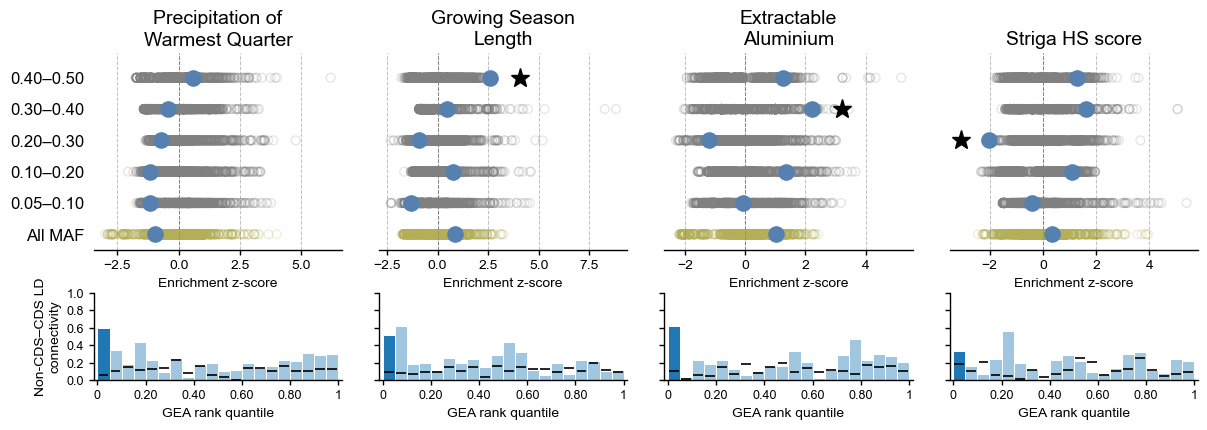

In [57]:
with gzip.open(results_json_file, 'rt') as handle:
    results_json = json.load(handle)
with open(ld_overlap_pkl_file, 'rb') as handle:
    ld_overlap_dict = pickle.load(handle)

environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]
figure_prefix = f'{enrichment_dir}/{contrast_id}.enrichment_and_overlap'
fig, axes = plot_enrichment_and_overlap(
    results_json, ld_overlap_dict, enrichment_environment_ids,
    environment_metadata_df, stratify_label_map,
    bottom_ylabel='Non-CDS–CDS LD\nconnectivity', bottom_ylim=(0, 1),
    bottom_yticks=(0, 0.2, 0.4, 0.6, 0.8, 1), show=False, apply_style=False,
)
fig.savefig(f'{figure_prefix}.pdf', bbox_inches='tight')
fig.savefig(f'{figure_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()

from scipy.stats import zscore

plot_frames = []
for stratum, label in stratify_label_map:
    for env_id in enrichment_environment_ids:
        result = results_json[stratum]
        values = [result['obs_values'][env_id]] + result['perm_values'][env_id]
        plot_frames.append(pd.DataFrame({
            'STRATUM': stratum, 'ENV_ID': env_id,
            'POINT_TYPE': ['observed'] + ['permutation'] * (len(values) - 1),
            'PERMUTATION_ID': [-1] + list(range(len(values) - 1)),
            'SCORE_RATIO': values, 'Z_SCORE': zscore(values),
            'P_VALUE': result['stat'][env_id]['pval'],
        }))
plot_data = pd.concat(plot_frames, ignore_index=True)
plot_data.to_csv(f'{figure_prefix}.enrichment.csv.gz', index=False, compression='gzip')
ld_plot_data = pd.concat([
    ld_overlap_dict[env_id][kind].assign(ENV_ID=env_id, POINT_TYPE=kind)
    for env_id in enrichment_environment_ids
    for kind in ['overlap_df', 'random_overlap_df']
], ignore_index=True)
ld_plot_data.to_csv(f'{figure_prefix}.ld_overlap.csv.gz', index=False, compression='gzip')


#### All flowering genes


#### 全部开花基因


In [58]:
contrast_id = 'flowering_non_coding_vs_coding'
contrast = contrasts_settings[contrast_id]
results_json_file = site_contrast_runner(
    contrast_id, contrast, context_df, enrichment_environment_ids, enrichment_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, enrichment_environment_ids, ld_df, ld_overlap_dir,
    bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
)


Permutations: 1000/1000 (100.0%) | elapsed 0.9s | 1163.80/s | ETA 0.0s
1000 permutations with pool_num=20: 0.90 s (1112.59 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1444.87/s | ETA 0.0s
1000 permutations with pool_num=20: 0.73 s (1362.93 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1398.33/s | ETA 0.0s
1000 permutations with pool_num=20: 0.76 s (1314.21 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1434.21/s | ETA 0.0s
1000 permutations with pool_num=20: 0.73 s (1361.15 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1466.13/s | ETA 0.0s
1000 permutations with pool_num=20: 0.72 s (1388.04 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 0.7s | 1398.41/s | ETA 0.0s
1000 permutations with pool_num=20: 0.76 s (1323.13 permutations/s)


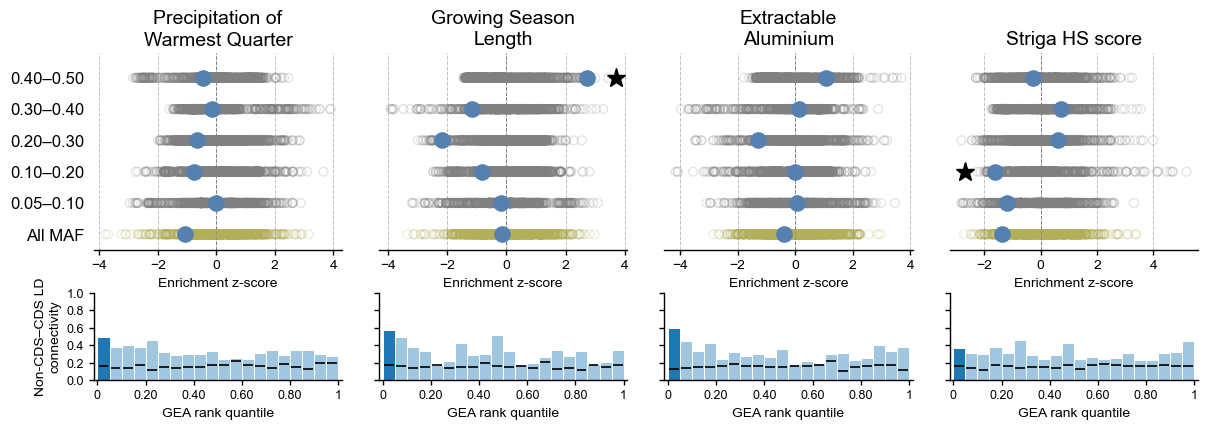

In [59]:
with gzip.open(results_json_file, 'rt') as handle:
    results_json = json.load(handle)
with open(ld_overlap_pkl_file, 'rb') as handle:
    ld_overlap_dict = pickle.load(handle)

environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]
figure_prefix = f'{enrichment_dir}/{contrast_id}.enrichment_and_overlap'
fig, axes = plot_enrichment_and_overlap(
    results_json, ld_overlap_dict, enrichment_environment_ids,
    environment_metadata_df, stratify_label_map,
    bottom_ylabel='Non-CDS–CDS LD\nconnectivity', bottom_ylim=(0, 1),
    bottom_yticks=(0, 0.2, 0.4, 0.6, 0.8, 1), show=False, apply_style=False,
)
fig.savefig(f'{figure_prefix}.pdf', bbox_inches='tight')
fig.savefig(f'{figure_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()

from scipy.stats import zscore

plot_frames = []
for stratum, label in stratify_label_map:
    for env_id in enrichment_environment_ids:
        result = results_json[stratum]
        values = [result['obs_values'][env_id]] + result['perm_values'][env_id]
        plot_frames.append(pd.DataFrame({
            'STRATUM': stratum, 'ENV_ID': env_id,
            'POINT_TYPE': ['observed'] + ['permutation'] * (len(values) - 1),
            'PERMUTATION_ID': [-1] + list(range(len(values) - 1)),
            'SCORE_RATIO': values, 'Z_SCORE': zscore(values),
            'P_VALUE': result['stat'][env_id]['pval'],
        }))
plot_data = pd.concat(plot_frames, ignore_index=True)
plot_data.to_csv(f'{figure_prefix}.enrichment.csv.gz', index=False, compression='gzip')
ld_plot_data = pd.concat([
    ld_overlap_dict[env_id][kind].assign(ENV_ID=env_id, POINT_TYPE=kind)
    for env_id in enrichment_environment_ids
    for kind in ['overlap_df', 'random_overlap_df']
], ignore_index=True)
ld_plot_data.to_csv(f'{figure_prefix}.ld_overlap.csv.gz', index=False, compression='gzip')


The upper panels compare observed enrichment with its permutation distribution across MAF strata; stars indicate P <0.05. Read the enrichment direction together with the raw non-CDS/CDS ratios in the saved results. Lower panels show cross-group linkage across GEA-rank bins, with shuffled-score references. LD alone does not establish a shared causal variant.


上半部分比较各MAF分层的观测富集与置换分布，星号表示P <0.05。结合保存结果中的原始非CDS/CDS比值判断关联强度方向。下半部分展示各GEA排名区间的跨组连锁联系及打乱分数后的参照。LD本身不能证明共享因果位点。
